# 4. Modelo base

## 4.1 Variable objetivo, partición, validación y búsqueda de `C`

- **Variable objetivo:** $y = 1$ si el cliente suscribió el depósito a término (`yes`) y $y = 0$ en caso contrario.
- **Partición:** cronológica 80/20 (sección 2), definida antes de cualquier preprocesamiento: el entrenamiento es el primer 80 % de los registros en orden temporal y la prueba, el último 20 %.
- **Validación cruzada:** del mismo tipo que la partición: `TimeSeriesSplit` de cinco pliegues sobre el entrenamiento ordenado, con separación de un día de contactos (sección 3).
- **Modelo:** regresión logística con penalización L2 dentro del `Pipeline` de la sección 3.7. El hiperparámetro de regularización `C` se elige con la validación temporal **minimizando la pérdida logarítmica** promedio de los pliegues: es la función que optimiza la propia regresión logística y una regla de puntuación propia (Gneiting y Raftery, 2007), que evalúa las probabilidades y no solo el orden. El AUC se reporta junto a ella, pero no sirve para elegir `C`: como solo mide el orden, no detecta coeficientes que asignan probabilidades extremas a un periodo nuevo.
- **Línea base trivial:** `DummyClassifier(strategy="prior")`, que predice siempre la clase mayoritaria y asigna a todos la misma probabilidad (la prevalencia de entrenamiento).
- **Conjunto de prueba:** se evalúa una sola vez, en la sección 4.4. En la sección 4.7.1 se recorre mes a mes y la recalibración usa solo las etiquetas de los meses ya cerrados, como ocurriría en operación, nunca las del mes que se predice.

La primera tabla muestra la búsqueda de `C`; la segunda, el resultado de cada pliegue con el valor elegido y con el que maximiza el AUC.

In [37]:
from sklearn.metrics import make_scorer
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

ESCORES = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0), "f1": make_scorer(f1_score, zero_division=0),
           "auc": "roc_auc", "auc_pr": "average_precision"}
NOMBRES_M = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "auc": "AUC",
             "auc_pr": "AUC-PR"}

grid = GridSearchCV(construir_modelo(), {"lr__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}, cv=tss,
                    scoring={"logloss": "neg_log_loss", "auc": "roc_auc", "auc_pr": "average_precision"},
                    refit="logloss", return_train_score=True)
grid.fit(X_tr, y_tr)
C_opt = grid.best_params_["lr__C"]
res_grid = pd.DataFrame(grid.cv_results_)
i_opt = grid.best_index_
i_auc = int(res_grid["mean_test_auc"].idxmax())   # el C que se elegiría maximizando el AUC
C_auc = float(res_grid.loc[i_auc, "param_lr__C"])
auc_val_opt = res_grid.loc[i_opt, "mean_test_auc"]
busqueda = pd.DataFrame({
    "C": [num_c(c) for c in res_grid["param_lr__C"].astype(float)],
    "Log-loss validación (media)": -res_grid["mean_test_logloss"],
    "Log-loss validación (desv. est.)": res_grid["std_test_logloss"],
    "AUC validación (media)": res_grid["mean_test_auc"], "AUC validación (desv. est.)": res_grid["std_test_auc"],
    "AUC entrenamiento (media)": res_grid["mean_train_auc"], "AUC-PR validación (media)": res_grid["mean_test_auc_pr"]})
tabla(busqueda.set_index("C"), dec=4)

pliegues_opt = esquema_tss[["Valida desde", "Valida hasta", "% positivos (validación)"]].copy()
for i_, C_ in ([(i_opt, C_opt), (i_auc, C_auc)] if i_auc != i_opt else [(i_opt, C_opt)]):
    pliegues_opt[f"Log-loss (C = {num_c(C_)})"] = [-res_grid.loc[i_, f"split{k}_test_logloss"]
                                                   for k in range(len(pliegues_opt))]
pliegues_opt["AUC"] = [res_grid.loc[i_opt, f"split{k}_test_auc"] for k in range(len(pliegues_opt))]
pliegues_opt["AUC-PR"] = [res_grid.loc[i_opt, f"split{k}_test_auc_pr"] for k in range(len(pliegues_opt))]
tabla(pliegues_opt, dec=3)

ll = -res_grid["mean_test_logloss"]
rango_auc = busqueda["AUC validación (media)"].max() - busqueda["AUC validación (media)"].min()
brecha = res_grid.loc[i_opt, "mean_train_auc"] - auc_val_opt
es_2008 = pliegues_opt["Valida hasta"].str.startswith("2008")
auc_2008 = pliegues_opt.loc[es_2008, "AUC"].mean()
auc_ultimo = pliegues_opt["AUC"].iloc[-1]
ll_ult = {C_: -res_grid.loc[i_, f"split{len(pliegues_opt) - 1}_test_logloss"] for i_, C_ in [(i_opt, C_opt), (i_auc, C_auc)]}
i_ent_ult, i_val_ult = list(tss.split(X_tr))[-1]
y_ult = y_tr.iloc[i_val_ult].to_numpy()
p_ult = {C_: construir_modelo(C=C_).fit(X_tr.iloc[i_ent_ult], y_tr.iloc[i_ent_ult]).predict_proba(X_tr.iloc[i_val_ult])[:, 1]
         for C_ in (C_opt, C_auc)}
extremos = p_ult[C_auc] > 0.9
interpretar(
    f"La pérdida logarítmica de validación es mínima con C = {num_c(C_opt)} ({num(ll[i_opt], 4)}), un valor interior "
    f"de la rejilla; con C = {num_c(C_auc)}, el que maximiza el AUC, sube a {num(ll[i_auc], 4)}. La diferencia se "
    f"concentra en el último pliegue ({pliegues_opt['Valida desde'].iloc[-1]} a {pliegues_opt['Valida hasta'].iloc[-1]}), "
    f"con {num(ll_ult[C_auc], 3)} frente a {num(ll_ult[C_opt], 3)}: ahí, con C = {num_c(C_auc)}, la probabilidad media "
    f"predicha es {num(p_ult[C_auc].mean(), 3)} para una tasa real de {num(y_ult.mean(), 3)}, y el "
    f"{pct(extremos.mean(), 0)} de los clientes recibe una probabilidad mayor que 0,9"
    + (f", aunque entre ellos solo suscribe el {pct(y_ult[extremos].mean(), 0)}" if extremos.any() else "")
    + f"; con C = {num_c(C_opt)} la probabilidad media es {num(p_ult[C_opt].mean(), 3)}. "
    f"El AUC, en cambio, apenas se mueve entre valores de C "
    f"(rango de {num(rango_auc, 4)}): con C = {num_c(C_opt)} es {num(auc_val_opt, 4)} y con C = {num_c(C_auc)}, "
    f"{num(res_grid.loc[i_auc, 'mean_test_auc'], 4)}, una diferencia menor que la desviación entre pliegues "
    f"({num(res_grid.loc[i_auc, 'std_test_auc'], 4)}). Los {int(es_2008.sum())} pliegues que validan en 2008 promedian un "
    f"AUC de {num(auc_2008, 3)} y el último llega a {num(auc_ultimo, 3)}; la brecha entre el AUC de entrenamiento y el "
    f"de validación es de {num(brecha, 4)}.",
    conectar('Lo anterior indica que', "El AUC solo mide el orden, así que no distingue un modelo con probabilidades razonables de otro que, con "
    "coeficientes grandes, asigna probabilidades extremas y equivocadas a un periodo nuevo. Eso pasa con poca "
    "regularización en el último pliegue, el único que valida con meses de 2009: los coeficientes de `month` y de "
    "las macro aprendidos con 2008 se extrapolan a condiciones que el modelo no vio. La pérdida logarítmica, que es "
    "la función que optimiza la regresión logística y una regla de puntuación propia, sí lo castiga. Dentro de "
    "2008 el modelo casi no ordena a los clientes del bloque siguiente con ningún valor de C."),
    conectar('De ahí que se opte por', f"Fijar C = {num_c(C_opt)} para el modelo base: minimiza la pérdida logarítmica, cuesta "
    f"{num(res_grid.loc[i_auc, 'mean_test_auc'] - auc_val_opt, 4)} de AUC de validación y estabiliza los "
    "coeficientes (sección 4.9.1). Leer las métricas de validación como una estimación conservadora y variable del "
    "desempeño en periodos futuros."))


,Log-loss validación (media),Log-loss validación (desv. est.),AUC validación (media),AUC validación (desv. est.),AUC entrenamiento (media),AUC-PR validación (media)
C,,,,,,
"0,001","0,2611","0,1051","0,5058","0,0738","0,5851","0,0906"
"0,01","0,2510","0,0848","0,5139","0,0869","0,5972","0,0968"
"0,1","0,3184","0,2148","0,5217","0,0887","0,6121","0,0956"
1,"0,4667","0,5089","0,5374","0,0753","0,6166","0,0961"
10,"0,4894","0,5528","0,5418","0,0744","0,6170","0,0975"
100,"0,4947","0,5629","0,5422","0,0740","0,6170","0,0972"


,Valida desde,Valida hasta,% positivos (validación),"Log-loss (C = 0,01)",Log-loss (C = 100),AUC,AUC-PR
Pliegue,,,,,,,
1,2008-05,2008-06,"3,880","0,166","0,171","0,499","0,039"
2,2008-06,2008-07,"6,047","0,234","0,230","0,484","0,059"
3,2008-07,2008-08,"5,920","0,225","0,230","0,492","0,061"
4,2008-08,2008-11,"5,446","0,216","0,223","0,417","0,045"
5,2008-11,2009-05,"14,026","0,414","1,620","0,677","0,279"


**Interpretación.** La pérdida logarítmica de validación es mínima con C = 0,01 (0,2510), un valor interior de la rejilla; con C = 100, el que maximiza el AUC, sube a 0,4947. La diferencia se concentra en el último pliegue (2008-11 a 2009-05), con 1,620 frente a 0,414: ahí, con C = 100, la probabilidad media predicha es 0,655 para una tasa real de 0,140, y el 49 % de los clientes recibe una probabilidad mayor que 0,9, aunque entre ellos solo suscribe el 21 %; con C = 0,01 la probabilidad media es 0,084. El AUC, en cambio, apenas se mueve entre valores de C (rango de 0,0364): con C = 0,01 es 0,5139 y con C = 100, 0,5422, una diferencia menor que la desviación entre pliegues (0,0740). Los 4 pliegues que validan en 2008 promedian un AUC de 0,473 y el último llega a 0,677; la brecha entre el AUC de entrenamiento y el de validación es de 0,0833.

Lo anterior indica que el AUC solo mide el orden, así que no distingue un modelo con probabilidades razonables de otro que, con coeficientes grandes, asigna probabilidades extremas y equivocadas a un periodo nuevo. Eso pasa con poca regularización en el último pliegue, el único que valida con meses de 2009: los coeficientes de `month` y de las macro aprendidos con 2008 se extrapolan a condiciones que el modelo no vio. La pérdida logarítmica, que es la función que optimiza la regresión logística y una regla de puntuación propia, sí lo castiga. Dentro de 2008 el modelo casi no ordena a los clientes del bloque siguiente con ningún valor de C.

De ahí que se opte por fijar C = 0,01 para el modelo base: minimiza la pérdida logarítmica, cuesta 0,0283 de AUC de validación y estabiliza los coeficientes (sección 4.9.1). Leer las métricas de validación como una estimación conservadora y variable del desempeño en periodos futuros.

## 4.2 Comparación con la línea base trivial en validación temporal

Antes de tocar el conjunto de prueba, se comparan el `DummyClassifier` y la regresión logística con las mismas métricas y los mismos pliegues temporales (umbral de clasificación 0,5).

In [38]:
def predicciones_validacion(modelo, X, y, cv):
    """Probabilidades de validación de cada pliegue temporal (solo entrenamiento), concatenadas."""
    indices, probs = [], []
    for i_ent, i_val in cv.split(X):
        m_ = clone(modelo).fit(X.iloc[i_ent], y.iloc[i_ent])
        indices.append(i_val)
        probs.append(m_.predict_proba(X.iloc[i_val])[:, 1])
    return np.concatenate(indices), np.concatenate(probs)


dummy = DummyClassifier(strategy="prior")
cv_d = cross_validate(dummy, X_tr, y_tr, cv=tss, scoring=ESCORES)
cv_m = cross_validate(construir_modelo(C=C_opt), X_tr, y_tr, cv=tss, scoring=ESCORES)
comp_cv = pd.DataFrame({
    "Dummy (media)": [cv_d[f"test_{m}"].mean() for m in ESCORES],
    "Regresión logística (media)": [cv_m[f"test_{m}"].mean() for m in ESCORES],
    "Regresión logística (desv. est.)": [cv_m[f"test_{m}"].std() for m in ESCORES]},
    index=[NOMBRES_M[m] for m in ESCORES])
comp_cv["Diferencia"] = comp_cv["Regresión logística (media)"] - comp_cv["Dummy (media)"]
tabla(comp_cv, dec=4)
idx_val, prob_val = predicciones_validacion(construir_modelo(C=C_opt), X_tr, y_tr, tss)

interpretar(
    f"En validación temporal, el Dummy obtiene accuracy de {num(comp_cv.loc['Accuracy', 'Dummy (media)'], 3)} sin "
    f"identificar a ningún cliente que suscribe. La regresión logística con umbral 0,5 llega a accuracy de "
    f"{num(comp_cv.loc['Accuracy', 'Regresión logística (media)'], 3)} (diferencia de "
    f"{num(comp_cv.loc['Accuracy', 'Diferencia'], 3)}), AUC de {num(comp_cv.loc['AUC', 'Regresión logística (media)'], 3)} "
    f"frente a 0,5 y AUC-PR de {num(comp_cv.loc['AUC-PR', 'Regresión logística (media)'], 3)} frente a "
    f"{num(comp_cv.loc['AUC-PR', 'Dummy (media)'], 3)}. Con umbral 0,5 el recall es "
    f"{num(comp_cv.loc['Recall', 'Regresión logística (media)'], 3)}: solo el {pct((prob_val >= 0.5).mean())} de las "
    "probabilidades de validación supera 0,5.",
    "Entonces, el accuracy apenas distingue un modelo útil de uno trivial; la mejora del modelo, cuando existe, se ve "
    "en AUC y AUC-PR. Con una prevalencia de entrenamiento baja, el modelo rara vez asigna probabilidades mayores a "
    "0,5, así que ese umbral deja escapar a casi todos los que suscriben.",
    "Por ello, se recomienda elegir el umbral de decisión con la validación temporal del entrenamiento (sección 4.3), "
    "en lugar de usar 0,5.")

,Dummy (media),Regresión logística (media),Regresión logística (desv. est.),Diferencia
Accuracy,"0,9294","0,9288","0,0367","-0,0005"
Precision,"0,0000","0,0667","0,1333","0,0667"
Recall,"0,0000","0,0039","0,0078","0,0039"
F1,"0,0000","0,0074","0,0147","0,0074"
AUC,"0,5000","0,5139","0,0869","0,0139"
AUC-PR,"0,0706","0,0968","0,0917","0,0261"


**Interpretación.** En validación temporal, el Dummy obtiene accuracy de 0,929 sin identificar a ningún cliente que suscribe. La regresión logística con umbral 0,5 llega a accuracy de 0,929 (diferencia de -0,001), AUC de 0,514 frente a 0,5 y AUC-PR de 0,097 frente a 0,071. Con umbral 0,5 el recall es 0,004: solo el 0,2 % de las probabilidades de validación supera 0,5.

Entonces, el accuracy apenas distingue un modelo útil de uno trivial; la mejora del modelo, cuando existe, se ve en AUC y AUC-PR. Con una prevalencia de entrenamiento baja, el modelo rara vez asigna probabilidades mayores a 0,5, así que ese umbral deja escapar a casi todos los que suscriben.

Por ello, se recomienda elegir el umbral de decisión con la validación temporal del entrenamiento (sección 4.3), en lugar de usar 0,5.

## 4.3 Umbral de decisión

Sin una matriz de costos de la campaña, se usa el umbral que maximiza el F1. Como la prevalencia y el contexto económico cambian en el tiempo (sección 3.6), el umbral se elige con el pliegue de validación temporal más reciente del entrenamiento, el más parecido al periodo siguiente, y no con el promedio de los pliegues, dominado por bloques de 2008 con otra prevalencia (sección 3). El umbral se fijó solo con datos de entrenamiento. Se conserva la clase sin reponderar (`class_weight=None`) para no distorsionar las probabilidades: el desbalance se atiende con el umbral y con métricas que no dependen de la clase mayoritaria.

In [39]:
rejilla_u = np.round(np.linspace(0.01, 0.90, 90), 2)
i_ent_rec, i_val_rec = list(tss.split(X_tr))[-1]
ajuste_umbral = TunedThresholdClassifierCV(construir_modelo(C=C_opt), scoring="f1", cv=[(i_ent_rec, i_val_rec)],
                                           thresholds=rejilla_u, store_cv_results=True).fit(X_tr, y_tr)
umbral = float(ajuste_umbral.best_threshold_)
modelo_final = ajuste_umbral.estimator_   # Pipeline reajustado con todo el entrenamiento
f1_05_rec = np.interp(0.5, ajuste_umbral.cv_results_["thresholds"], ajuste_umbral.cv_results_["scores"])
print(f"Pliegue más reciente: {periodo_tr.iloc[i_val_rec[0]]} a {periodo_tr.iloc[i_val_rec[-1]]} · umbral elegido = "
      f"{num(umbral, 2)} (F1 = {num(ajuste_umbral.best_score_, 3)}; con 0,5 el F1 sería {num(f1_05_rec, 3)})")

Pliegue más reciente: 2008-11 a 2009-05 · umbral elegido = 0,11 (F1 = 0,344; con 0,5 el F1 sería 0,037)


## 4.4 Métricas en el conjunto de prueba con intervalos de confianza

Se evalúan una sola vez, en prueba, el `DummyClassifier`, la regresión logística con umbral 0,5 y la regresión logística con el umbral elegido en la sección 4.3. Los intervalos de confianza del 95 % se obtienen con *bootstrap* percentil de 1 000 remuestras **por bloques de día** (Efron y Tibshirani, 1993): se remuestrean con reposición los días de contacto del periodo de prueba (`SEED`) y se conservan juntos los contactos de un mismo día, porque comparten condiciones y sus resultados están correlacionados (sección 4.10); un *bootstrap* registro por registro subestimaría la incertidumbre. Se usan las mismas remuestras para todos los modelos, lo que permite calcular también intervalos para las diferencias frente a la línea base.

In [40]:
dummy_ajustado = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
prob_te = modelo_final.predict_proba(X_te)[:, 1]
prob_dummy = dummy_ajustado.predict_proba(X_te)[:, 1]
pred_dummy = dummy_ajustado.predict(X_te)
pred_05 = (prob_te >= 0.5).astype(int)
pred_u = ajuste_umbral.predict(X_te)
yv = y_te.to_numpy()
assert np.array_equal(pred_u, (prob_te >= umbral).astype(int))

METRICAS = ["Accuracy", "Precision", "Recall", "F1", "AUC", "AUC-PR", "Brier"]


def metricas(y, prob, pred):
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return np.array([np.mean(pred == y), prec, rec, f1, roc_auc_score(y, prob), average_precision_score(y, prob),
                     np.mean((prob - y) ** 2)])


nombre_05 = "Regresión logística, umbral 0,5"
nombre_u = f"Regresión logística, umbral {num(umbral, 2)}"
modelos_eval = {"Dummy (prior)": (prob_dummy, pred_dummy), nombre_05: (prob_te, pred_05), nombre_u: (prob_te, pred_u)}
puntual = {k: metricas(yv, *v) for k, v in modelos_eval.items()}
assert np.isclose(puntual[nombre_05][3], f1_score(yv, pred_05))
assert np.isclose(puntual[nombre_05][6], brier_score_loss(yv, prob_te))

# Bootstrap por bloques de día (X_te conserva el orden temporal)
_, grupo_dia = np.unique(dia_te.to_numpy(), return_inverse=True)
bloques = [np.flatnonzero(grupo_dia == g) for g in range(grupo_dia.max() + 1)]
B = 1000
rng_boot = np.random.default_rng(SEED)
remuestras = [np.concatenate([bloques[g] for g in rng_boot.integers(0, len(bloques), size=len(bloques))])
              for _ in range(B)]
boot = {k: np.array([metricas(yv[ii], v[0][ii], v[1][ii]) for ii in remuestras]) for k, v in modelos_eval.items()}
print(f"Bootstrap: {B} remuestras de los {len(bloques)} días de contacto de la prueba "
      f"(mediana de {num(np.median([len(b) for b in bloques]))} registros por día).")


def con_ic(valor, muestras):
    lo, hi = np.percentile(muestras, [2.5, 97.5])
    return f"{num(valor, 3)} [{num(lo, 3)}; {num(hi, 3)}]"


tabla_test = pd.DataFrame({k: [con_ic(puntual[k][j], boot[k][:, j]) for j in range(len(METRICAS))]
                           for k in modelos_eval}, index=METRICAS).T
display(Markdown("**Métricas en prueba: valor puntual [IC 95 % bootstrap por bloques de día]**"))
tabla(tabla_test)

d_u = boot[nombre_u] - boot["Dummy (prior)"]
excluye_cero = all(np.percentile(d_u[:, METRICAS.index(m)], 2.5) > 0 for m in ["AUC", "AUC-PR", "Recall", "F1"])
difs = {}
for k in [nombre_05, nombre_u]:
    d = boot[k] - boot["Dummy (prior)"]
    difs[k] = [con_ic(puntual[k][j] - puntual["Dummy (prior)"][j], d[:, j]) for j in range(len(METRICAS))]
tabla_dif = pd.DataFrame(difs, index=METRICAS).T
display(Markdown("**Diferencia frente al Dummy (modelo − Dummy) [IC 95 % bootstrap pareado por bloques de día]**"))
tabla(tabla_dif)

P = {k: dict(zip(METRICAS, v)) for k, v in puntual.items()}
IC = {k: {m: np.percentile(boot[k][:, j], [2.5, 97.5]) for j, m in enumerate(METRICAS)} for k in boot}
prev_te = yv.mean()
marcados_u = pred_u.mean()
acc_m, acc_u, acc_d = P[nombre_05]["Accuracy"], P[nombre_u]["Accuracy"], P["Dummy (prior)"]["Accuracy"]


def frente_dummy(a):
    return "por debajo del" if a < acc_d - 0.005 else ("prácticamente igual al" if abs(a - acc_d) <= 0.005 else "por encima del")


interpretar(
    f"En prueba suscribe el {pct(prev_te)}. El Dummy obtiene accuracy de {num(acc_d, 3)} con recall y F1 de cero, "
    f"AUC de 0,5 y AUC-PR de {num(P['Dummy (prior)']['AUC-PR'], 3)}. La regresión logística logra AUC de "
    f"{con_ic(P[nombre_u]['AUC'], boot[nombre_u][:, 4])} y AUC-PR de {con_ic(P[nombre_u]['AUC-PR'], boot[nombre_u][:, 5])}, "
    f"{num(P[nombre_u]['AUC-PR'] / prev_te, 1)} veces la prevalencia. Con umbral 0,5: accuracy "
    f"{num(acc_m, 3)}, precisión {num(P[nombre_05]['Precision'], 3)}, recall {con_ic(P[nombre_05]['Recall'], boot[nombre_05][:, 2])} "
    f"y F1 {con_ic(P[nombre_05]['F1'], boot[nombre_05][:, 3])}. Con el umbral de {num(umbral, 2)}: accuracy "
    f"{num(acc_u, 3)}, precisión {num(P[nombre_u]['Precision'], 3)}, recall {con_ic(P[nombre_u]['Recall'], boot[nombre_u][:, 2])} "
    f"y F1 {con_ic(P[nombre_u]['F1'], boot[nombre_u][:, 3])}; este umbral marca como positivos al {pct(marcados_u)} "
    "de los clientes de prueba.",
    conectar('Por consiguiente,', ("Los intervalos de las diferencias frente al Dummy en AUC, AUC-PR, recall y F1 excluyen el cero: el modelo "
     "aprende señal que se sostiene en periodos posteriores. " if excluye_cero else
     "No todos los intervalos de las diferencias frente al Dummy excluyen el cero, así que la mejora debe leerse con "
     "cautela. ")
    + f"El accuracy con umbral 0,5 queda {frente_dummy(acc_m)} Dummy y con el umbral elegido queda "
    f"{frente_dummy(acc_u)} Dummy: esa métrica premia la clase mayoritaria, no la utilidad del modelo. "
    + (f"Además, el umbral aprendido en entrenamiento resulta demasiado bajo para la prevalencia de prueba: el "
       f"recall es alto porque se marca como positivo al {pct(marcados_u)} de los clientes, no porque el modelo "
       "discrimine mejor. " if marcados_u > 0.6 else
       (f"El umbral marca como positivos al {pct(marcados_u)} de los clientes, menos que la prevalencia de prueba "
        f"({pct(prev_te)}): con probabilidades desplazadas hacia abajo por el cambio de prevalencia (sección 4.7), un "
        "umbral fijado en entrenamiento resulta exigente en prueba. " if marcados_u < prev_te else
        f"El umbral aprendido en entrenamiento marca como positivos al {pct(marcados_u)} de los clientes de prueba, "
        f"frente a una prevalencia del {pct(prev_te)}: gana recall a costa de precisión. "))
    + f"En prueba, el F1 con el umbral elegido es "
    + ("mayor" if P[nombre_u]["F1"] > P[nombre_05]["F1"] + 0.005 else
       ("menor" if P[nombre_u]["F1"] < P[nombre_05]["F1"] - 0.005 else "similar"))
    + f" que con 0,5 ({num(P[nombre_u]['F1'], 3)} frente a {num(P[nombre_05]['F1'], 3)}); el umbral se mantiene tal "
    "como se fijó en entrenamiento."),
    conectar('Por tal motivo, se opta por', "Tomar el AUC y el AUC-PR como métricas principales del modelo base y, como el umbral óptimo cambia con la "
    "prevalencia, no fijarlo de una vez: recalibrar el modelo con los meses ya cerrados y elegir el umbral sobre "
    "esas probabilidades (sección 4.7.1)."))

Bootstrap: 1000 remuestras de los 323 días de contacto de la prueba (mediana de 13 registros por día).


**Métricas en prueba: valor puntual [IC 95 % bootstrap por bloques de día]**

,Accuracy,Precision,Recall,F1,AUC,AUC-PR,Brier
Dummy (prior),"0,692 [0,611; 0,750]","0,000 [0,000; 0,000]","0,000 [0,000; 0,000]","0,000 [0,000; 0,000]","0,500 [0,500; 0,500]","0,308 [0,250; 0,389]","0,273 [0,222; 0,344]"
"Regresión logística, umbral 0,5","0,710 [0,636; 0,763]","0,750 [0,693; 0,804]","0,087 [0,066; 0,114]","0,157 [0,122; 0,198]","0,710 [0,672; 0,731]","0,548 [0,502; 0,595]","0,206 [0,173; 0,253]"
"Regresión logística, umbral 0,11","0,581 [0,548; 0,613]","0,403 [0,351; 0,462]","0,751 [0,708; 0,791]","0,525 [0,470; 0,580]","0,710 [0,672; 0,731]","0,548 [0,502; 0,595]","0,206 [0,173; 0,253]"


**Diferencia frente al Dummy (modelo − Dummy) [IC 95 % bootstrap pareado por bloques de día]**

,Accuracy,Precision,Recall,F1,AUC,AUC-PR,Brier
"Regresión logística, umbral 0,5","0,018 [0,011; 0,027]","0,750 [0,693; 0,804]","0,087 [0,066; 0,114]","0,157 [0,122; 0,198]","0,210 [0,172; 0,231]","0,240 [0,188; 0,273]","-0,067 [-0,091; -0,049]"
"Regresión logística, umbral 0,11","-0,111 [-0,157; -0,049]","0,403 [0,351; 0,462]","0,751 [0,708; 0,791]","0,525 [0,470; 0,580]","0,210 [0,172; 0,231]","0,240 [0,188; 0,273]","-0,067 [-0,091; -0,049]"


**Interpretación.** En prueba suscribe el 30,8 %. El Dummy obtiene accuracy de 0,692 con recall y F1 de cero, AUC de 0,5 y AUC-PR de 0,308. La regresión logística logra AUC de 0,710 [0,672; 0,731] y AUC-PR de 0,548 [0,502; 0,595], 1,8 veces la prevalencia. Con umbral 0,5: accuracy 0,710, precisión 0,750, recall 0,087 [0,066; 0,114] y F1 0,157 [0,122; 0,198]. Con el umbral de 0,11: accuracy 0,581, precisión 0,403, recall 0,751 [0,708; 0,791] y F1 0,525 [0,470; 0,580]; este umbral marca como positivos al 57,4 % de los clientes de prueba.

Por consiguiente, los intervalos de las diferencias frente al Dummy en AUC, AUC-PR, recall y F1 excluyen el cero: el modelo aprende señal que se sostiene en periodos posteriores. El accuracy con umbral 0,5 queda por encima del Dummy y con el umbral elegido queda por debajo del Dummy: esa métrica premia la clase mayoritaria, no la utilidad del modelo. El umbral aprendido en entrenamiento marca como positivos al 57,4 % de los clientes de prueba, frente a una prevalencia del 30,8 %: gana recall a costa de precisión. En prueba, el F1 con el umbral elegido es mayor que con 0,5 (0,525 frente a 0,157); el umbral se mantiene tal como se fijó en entrenamiento.

Por tal motivo, se opta por tomar el AUC y el AUC-PR como métricas principales del modelo base y, como el umbral óptimo cambia con la prevalencia, no fijarlo de una vez: recalibrar el modelo con los meses ya cerrados y elegir el umbral sobre esas probabilidades (sección 4.7.1).

## 4.5 Matriz de confusión

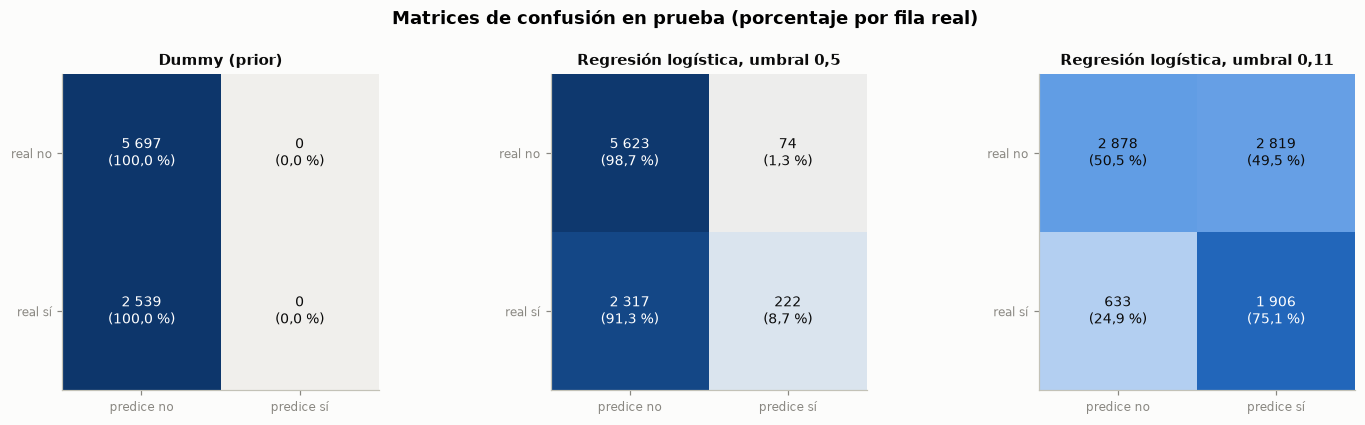

**Interpretación.** Con umbral 0,5 el modelo detecta 222 de los 2 539 clientes que suscriben y marca 74 falsos positivos: de sus 296 llamadas recomendadas, el 75,0 % terminaría en suscripción. Con el umbral de 0,11 detecta 1 906 (75,1 %) a cambio de 2 819 falsos positivos: de 4 725 llamadas, el 40,3 % terminaría en suscripción. Si se llamara al azar, la tasa de éxito sería del 30,8 %. El Dummy no recomienda ninguna llamada.

En la práctica, con umbral 0,5 la lista es corta y más precisa que llamar al azar (2,4 veces la tasa base), pero deja por fuera a la mayoría de quienes suscriben. Con el umbral elegido se llamaría al 57,4 % de los clientes y se capturaría el 75,1 % de las suscripciones, con una tasa de éxito 1,3 veces la de llamar al azar.

En consecuencia, se decide usar la matriz de confusión para estimar el costo y el beneficio de la campaña cuando el banco aporte los valores económicos, y elegir el punto de operación según la capacidad de llamadas, no con un umbral fijo.

In [41]:
fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, (nombre, (_, pred)) in zip(axs, modelos_eval.items()):
    cm = confusion_matrix(yv, pred, labels=[0, 1])
    filas_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(filas_pct, cmap=CMAP_SEQ, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{num(cm[i, j])}\n({pct(filas_pct[i, j])})", ha="center", va="center", fontsize=9,
                    color="white" if filas_pct[i, j] > 0.6 else TINTA)
    ax.set_xticks([0, 1], ["predice no", "predice sí"])
    ax.set_yticks([0, 1], ["real no", "real sí"])
    ax.grid(False)
    ax.set_title(nombre, fontsize=9.5)
fig.suptitle("Matrices de confusión en prueba (porcentaje por fila real)")
plt.tight_layout()
plt.show()

cm_u = confusion_matrix(yv, pred_u, labels=[0, 1])
cm_5 = confusion_matrix(yv, pred_05, labels=[0, 1])
llamadas_u, llamadas_5 = cm_u[:, 1].sum(), cm_5[:, 1].sum()
interpretar(
    f"Con umbral 0,5 el modelo detecta {num(cm_5[1, 1])} de los {num(cm_5[1].sum())} clientes que suscriben y marca "
    f"{num(cm_5[0, 1])} falsos positivos: de sus {num(llamadas_5)} llamadas recomendadas, el "
    f"{pct(cm_5[1, 1] / llamadas_5 if llamadas_5 else 0)} terminaría en suscripción. Con el umbral de {num(umbral, 2)} "
    f"detecta {num(cm_u[1, 1])} ({pct(cm_u[1, 1] / cm_u[1].sum())}) a cambio de {num(cm_u[0, 1])} falsos positivos: de "
    f"{num(llamadas_u)} llamadas, el {pct(cm_u[1, 1] / llamadas_u if llamadas_u else 0)} terminaría en suscripción. Si se "
    f"llamara al azar, la tasa de éxito sería del {pct(prev_te)}. El Dummy no recomienda ninguna llamada.",
    conectar('En la práctica,', (f"Con umbral 0,5 la lista es corta y más precisa que llamar al azar ("
     f"{num((cm_5[1, 1] / llamadas_5) / prev_te if llamadas_5 else 0, 1)} veces la tasa base)"
     + (", pero deja por fuera a la mayoría de quienes suscriben. " if cm_5[1, 1] / cm_5[1].sum() < 0.5 else ". ")
     if llamadas_5 else "")
    + (f"Con el umbral elegido, en cambio, se llamaría al {pct(llamadas_u / len(yv))} de los clientes: el modelo pierde "
       "selectividad porque el umbral se aprendió con una prevalencia mucho menor."
       if llamadas_u / len(yv) > 0.6 else
       f"Con el umbral elegido se llamaría al {pct(llamadas_u / len(yv))} de los clientes y se capturaría el "
       f"{pct(cm_u[1, 1] / cm_u[1].sum())} de las suscripciones, con una tasa de éxito "
       f"{num((cm_u[1, 1] / llamadas_u) / prev_te if llamadas_u else 0, 1)} veces la de llamar al azar.")),
    conectar('En consecuencia, se decide', "Usar la matriz de confusión para estimar el costo y el beneficio de la campaña cuando el banco aporte los "
    "valores económicos, y elegir el punto de operación según la capacidad de llamadas, no con un umbral fijo."))

## 4.6 Curvas ROC y precisión-recall

Con clases desbalanceadas, la curva precisión-recall es más informativa que la ROC, porque su línea base es la prevalencia y no 0,5 (Saito y Rehmsmeier, 2015).

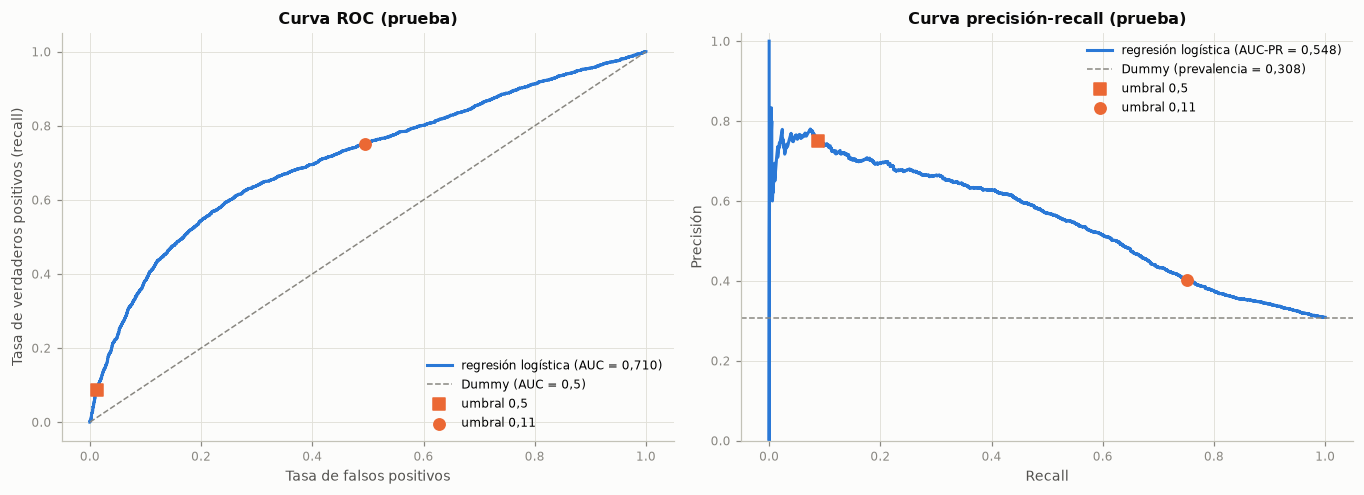

**Interpretación.** La curva ROC queda por encima de la diagonal (AUC = 0,710). En la curva precisión-recall, con un recall de 20 % la precisión es 0,69, con 50 % es 0,57 y para recall altos se acerca a la prevalencia (0,308). En el 5 % de clientes con mayor probabilidad suscribe el 72,3 % y el 87,9 % tuvo éxito en una campaña anterior, frente al 14,6 % en toda la prueba.

Esto significa que el modelo identifica mejor a un grupo reducido de clientes muy probables, definido sobre todo por el historial con el banco, que es la señal que mejor se transfiere de un periodo a otro; para el resto, los perfiles de quienes suscriben y quienes no se parecen mucho.

Por lo anterior, si la capacidad de llamadas es limitada, conviene priorizar por probabilidad y elegir el punto de la curva PR que corresponda a esa capacidad, sin forzar recall altos con este modelo.

In [42]:
fpr, tpr, _ = roc_curve(yv, prob_te)
prec_c, rec_c, _ = precision_recall_curve(yv, prob_te)
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
axs[0].plot(fpr, tpr, color=AZUL, label=f"regresión logística (AUC = {num(P[nombre_u]['AUC'], 3)})")
axs[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Dummy (AUC = 0,5)")
axs[1].plot(rec_c, prec_c, color=AZUL, label=f"regresión logística (AUC-PR = {num(P[nombre_u]['AUC-PR'], 3)})")
axs[1].axhline(prev_te, color=GRIS, ls="--", lw=1, label=f"Dummy (prevalencia = {num(prev_te, 3)})")
for pred, etiqueta, marca in [(pred_05, "umbral 0,5", "s"), (pred_u, f"umbral {num(umbral, 2)}", "o")]:
    cm_ = confusion_matrix(yv, pred, labels=[0, 1])
    tpr_p, fpr_p = cm_[1, 1] / cm_[1].sum(), cm_[0, 1] / cm_[0].sum()
    prec_p = cm_[1, 1] / cm_[:, 1].sum() if cm_[:, 1].sum() else 0
    axs[0].scatter(fpr_p, tpr_p, color=NARANJA, marker=marca, s=55, zorder=3, label=etiqueta)
    axs[1].scatter(tpr_p, prec_p, color=NARANJA, marker=marca, s=55, zorder=3, label=etiqueta)
axs[0].set_xlabel("Tasa de falsos positivos")
axs[0].set_ylabel("Tasa de verdaderos positivos (recall)")
axs[0].set_title("Curva ROC (prueba)")
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precisión")
axs[1].set_title("Curva precisión-recall (prueba)")
axs[1].set_ylim(0, 1.02)
for a in axs:
    a.legend(loc="lower right" if a is axs[0] else "upper right")
plt.tight_layout()
plt.show()


def precision_en_recall(r):
    i = np.flatnonzero(rec_c >= r)[-1]   # recall está en orden decreciente
    return prec_c[i]


top5 = prob_te >= np.quantile(prob_te, 0.95)
share_success_top = (X_te["poutcome"].to_numpy()[top5] == "success").mean()
share_success_te = (X_te["poutcome"] == "success").mean()
prev_top5 = yv[top5].mean()
interpretar(
    f"La curva ROC queda por encima de la diagonal (AUC = {num(P[nombre_u]['AUC'], 3)}). En la curva "
    f"precisión-recall, con un recall de 20 % la precisión es {num(precision_en_recall(0.2), 2)}, con 50 % es "
    f"{num(precision_en_recall(0.5), 2)} y para recall altos se acerca a la prevalencia ({num(prev_te, 3)}). En el "
    f"5 % de clientes con mayor probabilidad suscribe el {pct(prev_top5)} y el {pct(share_success_top)} tuvo éxito en "
    f"una campaña anterior, frente al {pct(share_success_te)} en toda la prueba.",
    conectar('Esto significa que', "El modelo identifica mejor a un grupo reducido de clientes muy probables, definido sobre todo por el historial "
    "con el banco, que es la señal que mejor se transfiere de un periodo a otro; para el resto, los perfiles de "
    "quienes suscriben y quienes no se parecen mucho."),
    conectar('Por lo anterior,', "Si la capacidad de llamadas es limitada, conviene priorizar por probabilidad y elegir el punto de la curva PR "
    "que corresponda a esa capacidad, sin forzar recall altos con este modelo."))

## 4.7 Calibración

La calibración compara la probabilidad predicha con la frecuencia observada de suscripción en diez grupos de igual tamaño (cuantiles de la probabilidad). El puntaje de Brier mide el error cuadrático de las probabilidades; el *Brier skill score* (BSS) lo compara con el del Dummy, que asigna a todos la prevalencia de entrenamiento (0 = igual que el Dummy, 1 = perfecto).

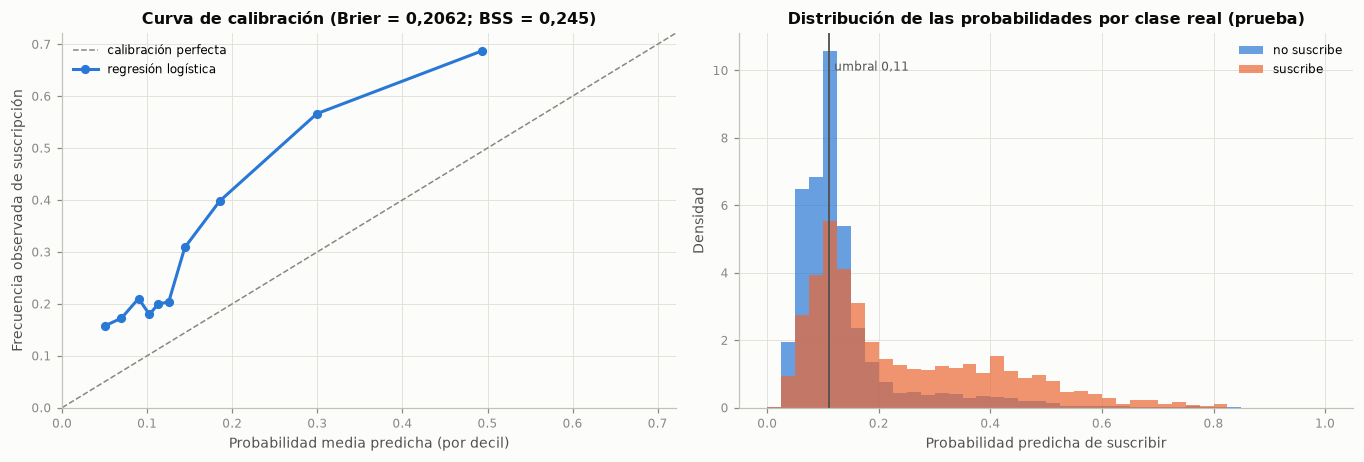

**Interpretación.** La probabilidad media predicha en prueba es 0,167 frente a una tasa observada de 0,308 (diferencia de -0,141). En 10 de los 10 deciles la frecuencia observada supera a la predicha; la desviación absoluta media es de 0,141 y la máxima de 0,267. El Brier del modelo es 0,2062 frente a 0,2730 del Dummy (BSS = 0,245).

Es decir, el modelo subestima la probabilidad de suscribir en prueba: aprendió con una tasa base menor y no puede anticipar el aumento de la prevalencia. Por eso sus probabilidades sirven para ordenar clientes, pero no se pueden leer directamente como frecuencias esperadas en un periodo nuevo sin recalibrar.

Por ello, se opta por mantener la regresión logística sin reponderar clases y corregir el nivel de las probabilidades con la recalibración mensual del intercepto (sección 4.7.1).

In [43]:
frac_pos, prob_media = calibration_curve(yv, prob_te, n_bins=10, strategy="quantile")
bss = 1 - P[nombre_u]["Brier"] / P["Dummy (prior)"]["Brier"]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3))
lim = max(prob_media.max(), frac_pos.max()) * 1.05
axs[0].plot([0, lim], [0, lim], color=GRIS, ls="--", lw=1, label="calibración perfecta")
axs[0].plot(prob_media, frac_pos, color=AZUL, marker="o", ms=5, label="regresión logística")
axs[0].set_xlabel("Probabilidad media predicha (por decil)")
axs[0].set_ylabel("Frecuencia observada de suscripción")
axs[0].set_title(f"Curva de calibración (Brier = {num(P[nombre_u]['Brier'], 4)}; BSS = {num(bss, 3)})")
axs[0].legend(loc="upper left")
axs[0].set_xlim(0, lim)
axs[0].set_ylim(0, lim)
bins_h = np.linspace(0, 1, 41)
for clase in (0, 1):
    axs[1].hist(prob_te[yv == clase], bins=bins_h, color=COLOR_Y[clase], alpha=0.7, label=ETIQUETA_Y[clase],
                density=True)
axs[1].axvline(umbral, color=TINTA_2, lw=1.2)
axs[1].text(umbral + 0.01, axs[1].get_ylim()[1] * 0.9, f"umbral {num(umbral, 2)}", fontsize=8, color=TINTA_2)
axs[1].set_xlabel("Probabilidad predicha de suscribir")
axs[1].set_ylabel("Densidad")
axs[1].set_title("Distribución de las probabilidades por clase real (prueba)")
axs[1].legend()
plt.tight_layout()
plt.show()

err_cal = np.abs(frac_pos - prob_media)
sesgo_cal = prob_te.mean() - prev_te
deciles_bajo = int((frac_pos > prob_media).sum())
interpretar(
    f"La probabilidad media predicha en prueba es {num(prob_te.mean(), 3)} frente a una tasa observada de "
    f"{num(prev_te, 3)} (diferencia de {num(sesgo_cal, 3)}). En {deciles_bajo} de los {len(frac_pos)} deciles la "
    f"frecuencia observada supera a la predicha; la desviación absoluta media es de {num(err_cal.mean(), 3)} y la "
    f"máxima de {num(err_cal.max(), 3)}. El Brier del modelo es {num(P[nombre_u]['Brier'], 4)} frente a "
    f"{num(P['Dummy (prior)']['Brier'], 4)} del Dummy (BSS = {num(bss, 3)}).",
    conectar('Es decir,', ("El modelo subestima la probabilidad de suscribir en prueba: aprendió con una tasa base menor y no puede "
     "anticipar el aumento de la prevalencia. " if sesgo_cal < -0.02 else
     ("El modelo sobrestima la probabilidad de suscribir en prueba. " if sesgo_cal > 0.02 else
      "La probabilidad media predicha coincide con la tasa observada en prueba. "))
    + "Por eso sus probabilidades sirven para ordenar clientes, pero no se pueden leer directamente como "
    "frecuencias esperadas en un periodo nuevo sin recalibrar."),
    conectar('Por ello, se opta por', "Mantener la regresión logística sin reponderar clases y corregir el nivel de las probabilidades con la "
    "recalibración mensual del intercepto (sección 4.7.1)."))

### 4.7.1 Recalibración del intercepto con los meses ya cerrados

El modelo subestima la probabilidad en prueba porque la prevalencia cambia entre periodos (sección 3.6.3). La corrección más directa, sin información del futuro, es la **recalibración del intercepto** (*recalibration-in-the-large*; Steyerberg, 2019), equivalente a ajustar las probabilidades a una nueva tasa base (Saerens et al., 2002): se suma un desplazamiento δ al logit de cada predicción y se dejan fijos los demás coeficientes, así que el orden de los clientes dentro de un mes no cambia.

- **Datos recientes:** al cerrar cada mes, el banco conoce sus resultados. Antes de puntuar un mes, δ se estima por máxima verosimilitud con los contactos del mes cerrado anterior; si ese mes tiene menos de 500 contactos, se agregan los meses previos hasta reunirlos (con 500 contactos, el error estándar de una tasa del 30 % es de unos 2 puntos). Nunca se usan las etiquetas del mes que se predice.
- **Umbral:** se vuelve a elegir con el criterio F1 en el pliegue de validación más reciente del entrenamiento, recalibrado de la misma forma, de modo que ninguna decisión usa la prueba.
- **Evaluación:** se compara con el modelo sin recalibrar, con los mismos intervalos *bootstrap* por bloques de día de la sección 4.4.

Umbral F1 con la validación recalibrada: 0,13 · desplazamientos del intercepto en prueba: de -0,12 a 1,78 (mediana 1,35)


**Prueba: valor puntual [IC 95 % bootstrap por bloques de día]**

,Accuracy,Precision,Recall,F1,AUC,AUC-PR,Brier
"Regresión logística, umbral 0,11 (sin recalibrar)","0,581 [0,548; 0,613]","0,403 [0,351; 0,462]","0,751 [0,708; 0,791]","0,525 [0,470; 0,580]","0,710 [0,672; 0,731]","0,548 [0,502; 0,595]","0,206 [0,173; 0,253]"
"Recalibrada por mes, umbral 0,5","0,740 [0,672; 0,786]","0,608 [0,578; 0,638]","0,438 [0,377; 0,498]","0,509 [0,462; 0,553]","0,752 [0,697; 0,776]","0,580 [0,540; 0,621]","0,178 [0,151; 0,215]"
"Recalibrada por mes, umbral 0,13","0,593 [0,516; 0,650]","0,421 [0,391; 0,454]","0,849 [0,782; 0,910]","0,563 [0,524; 0,602]","0,752 [0,697; 0,776]","0,580 [0,540; 0,621]","0,178 [0,151; 0,215]"
"Diferencia (recalibrada con 0,5 − sin recalibrar)","0,159 [0,116; 0,192]","0,204 [0,145; 0,257]","-0,312 [-0,362; -0,265]","-0,015 [-0,057; 0,019]","0,042 [0,022; 0,059]","0,032 [0,016; 0,047]","-0,028 [-0,042; -0,019]"
"Diferencia (recalibrada con 0,13 − sin recalibrar)","0,012 [-0,038; 0,047]","0,017 [-0,016; 0,044]","0,098 [0,050; 0,148]","0,038 [0,015; 0,058]","0,042 [0,022; 0,059]","0,032 [0,016; 0,047]","-0,028 [-0,042; -0,019]"


**Matriz de confusión de los puntos de operación recalibrados y diferencia de accuracy frente al Dummy [IC 95 % bootstrap pareado por bloques de día]**

,Verdaderos positivos,Falsos positivos,Falsos negativos,Verdaderos negativos,% de clientes marcados,Accuracy − Dummy [IC 95 %]
"Recalibrada por mes, umbral 0,5",1 113,718,1 426,4 979,"22,2","0,048 [0,031; 0,073]"
"Recalibrada por mes, umbral 0,13",2 155,2 968,384,2 729,"62,2","-0,099 [-0,128; -0,063]"


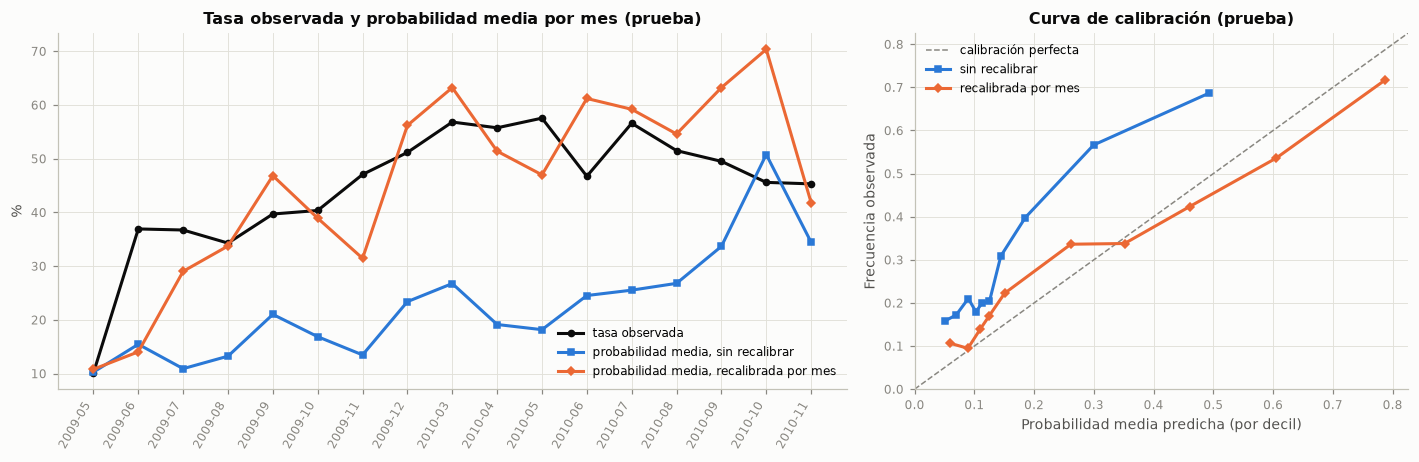

**Interpretación.** Con el desplazamiento mensual del intercepto, la probabilidad media en prueba pasa de 0,167 a 0,300 (tasa observada: 0,308) y el error absoluto medio entre la probabilidad media y la tasa de cada mes baja de 22,8 a 8,5 puntos. El Brier pasa de 0,206 a 0,178 (diferencia [-0,042; -0,019]) y el AUC global, de 0,710 a 0,752, aunque el AUC promedio dentro de cada mes no cambia (0,625). Con el umbral de 0,5 sobre las probabilidades recalibradas, el accuracy es 0,740, frente a 0,692 del Dummy (diferencia [0,031; 0,073]), la precisión 0,608, el recall 0,438 y el F1 0,509. Con el umbral de F1 elegido en la validación recalibrada (0,13), el F1 sube a 0,563 (diferencia frente al modelo sin recalibrar [0,015; 0,058]) y el recall a 0,849, pero se marca al 62,2 % de los clientes y el accuracy baja a 0,593.

Entonces, la recalibración corrige el desplazamiento de la clase sin usar información del futuro: cada mes toma su tasa base de los meses ya cerrados, cuyos resultados el banco conoce al cerrar la campaña. Como solo mueve el intercepto, no cambia el orden de los clientes dentro de un mes; la mejora del AUC global viene de ordenar mejor los meses entre sí. Los intervalos de la diferencia en Brier excluyen el cero, así que la mejora de las probabilidades no se explica por azar. El error que queda aparece en los meses en que la tasa cambia mucho respecto al mes anterior: la corrección siempre llega con un mes de retraso. Con probabilidades calibradas, además, 0,5 es el umbral que maximiza la exactitud esperada sin ajustarlo con datos: se marca a un cliente cuando es más probable que suscriba que no. El umbral de F1, en cambio, no cuenta los verdaderos negativos y marca a muchos clientes para encontrar a la mayoría de los suscriptores: gana recall a costa de accuracy.

Con base en esto, se propone incorporar la recalibración mensual del intercepto al uso del modelo base, con dos puntos de operación: 0,5 como predeterminado (máxima exactitud esperada) y el umbral de F1 cuando se prioriza encontrar suscriptores; la elección final depende del costo de una llamada frente al valor de un depósito. La sección 4.11 aplica la misma recalibración a modelos más flexibles para compararlos en igualdad de condiciones.

In [44]:
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit

N_MIN_RECAL = 500   # error estándar de la tasa de referencia de unos 2 puntos con una prevalencia del 30 %


def desplazamiento_intercepto(z, y):
    """Desplazamiento del intercepto que maximiza la verosimilitud de y, con los demás coeficientes fijos."""
    return minimize_scalar(lambda d: -np.sum(y * (z + d) - np.logaddexp(0, z + d)), bounds=(-10, 10),
                           method="bounded").x


def recalibrar_por_mes(z, y, periodos, evaluar, n_min=N_MIN_RECAL):
    """Suma a los logits de cada mes evaluado el desplazamiento estimado con el mes cerrado anterior
    (y con los previos, si hace falta, hasta reunir n_min contactos). Solo usa etiquetas de meses ya cerrados."""
    orden = list(dict.fromkeys(periodos))
    z_rec, deltas = z.copy(), {}
    for q in dict.fromkeys(periodos[evaluar]):
        referencia = np.zeros(len(periodos), dtype=bool)
        for q_prev in reversed(orden[:orden.index(q)]):
            referencia |= periodos == q_prev
            if referencia.sum() >= n_min:
                break
        deltas[q] = desplazamiento_intercepto(z[referencia], y[referencia])
        z_rec[(periodos == q) & evaluar] += deltas[q]
    return expit(z_rec[evaluar]), pd.Series(deltas)


def logit_seguro(p):
    return logit(np.clip(p, 1e-12, 1 - 1e-12))


# 1) Umbral con el pliegue de validación más reciente, ya recalibrado (solo entrenamiento)
m_pliegue = construir_modelo(C=C_opt).fit(X_tr.iloc[i_ent_rec], y_tr.iloc[i_ent_rec])
en_val = np.zeros(len(X_tr), dtype=bool)
en_val[i_val_rec] = True
prob_val_rec, _ = recalibrar_por_mes(logit_seguro(m_pliegue.predict_proba(X_tr)[:, 1]), y_tr.to_numpy(),
                                     periodo_tr.to_numpy(), en_val)
f1_val_rec = [f1_score(y_tr.to_numpy()[en_val], (prob_val_rec >= u).astype(int), zero_division=0) for u in rejilla_u]
umbral_rec = float(rejilla_u[int(np.argmax(f1_val_rec))])

# 2) Prueba: cada mes usa el desplazamiento de los meses cerrados anteriores (entrenamiento o prueba ya vencida)
y_ord = np.r_[y_tr.to_numpy(), yv]
periodo_ord = np.r_[periodo_tr.to_numpy(), periodo_te.to_numpy()]
en_te = np.r_[np.zeros(len(X_tr), dtype=bool), np.ones(len(X_te), dtype=bool)]
z_ord = logit_seguro(modelo_final.predict_proba(pd.concat([X_tr, X_te]))[:, 1])
prob_te_rec, deltas_te = recalibrar_por_mes(z_ord, y_ord, periodo_ord, en_te)
pred_te_rec = (prob_te_rec >= umbral_rec).astype(int)
pred_te_rec05 = (prob_te_rec >= 0.5).astype(int)   # con probabilidades calibradas: máxima exactitud esperada
print(f"Umbral F1 con la validación recalibrada: {num(umbral_rec, 2)} · desplazamientos del intercepto en prueba: "
      f"de {num(deltas_te.min(), 2)} a {num(deltas_te.max(), 2)} (mediana {num(deltas_te.median(), 2)})")

nombre_rec = f"Recalibrada por mes, umbral {num(umbral_rec, 2)}"
puntual[nombre_rec] = metricas(yv, prob_te_rec, pred_te_rec)
boot[nombre_rec] = np.array([metricas(yv[ii], prob_te_rec[ii], pred_te_rec[ii]) for ii in remuestras])
P[nombre_rec] = dict(zip(METRICAS, puntual[nombre_rec]))
nombre_rec05 = "Recalibrada por mes, umbral 0,5"
puntual[nombre_rec05] = metricas(yv, prob_te_rec, pred_te_rec05)
boot[nombre_rec05] = np.array([metricas(yv[ii], prob_te_rec[ii], pred_te_rec05[ii]) for ii in remuestras])
P[nombre_rec05] = dict(zip(METRICAS, puntual[nombre_rec05]))
d_rec05 = boot[nombre_rec05] - boot[nombre_u]
d_rec = boot[nombre_rec] - boot[nombre_u]
comparacion_rec = pd.DataFrame({
    nombre_u + " (sin recalibrar)": [con_ic(puntual[nombre_u][j], boot[nombre_u][:, j]) for j in range(len(METRICAS))],
    nombre_rec05: [con_ic(puntual[nombre_rec05][j], boot[nombre_rec05][:, j]) for j in range(len(METRICAS))],
    nombre_rec: [con_ic(puntual[nombre_rec][j], boot[nombre_rec][:, j]) for j in range(len(METRICAS))],
    "Diferencia (recalibrada con 0,5 − sin recalibrar)": [
        con_ic(puntual[nombre_rec05][j] - puntual[nombre_u][j], d_rec05[:, j]) for j in range(len(METRICAS))],
    f"Diferencia (recalibrada con {num(umbral_rec, 2)} − sin recalibrar)": [
        con_ic(puntual[nombre_rec][j] - puntual[nombre_u][j], d_rec[:, j]) for j in range(len(METRICAS))]},
    index=METRICAS).T
display(Markdown("**Prueba: valor puntual [IC 95 % bootstrap por bloques de día]**"))
tabla(comparacion_rec)

filas_op = {}
for nombre_op, pred_op in ((nombre_rec05, pred_te_rec05), (nombre_rec, pred_te_rec)):
    tn_op, fp_op, fn_op, tp_op = confusion_matrix(yv, pred_op, labels=[0, 1]).ravel()
    lo_op, hi_op = np.percentile(boot[nombre_op][:, 0] - boot["Dummy (prior)"][:, 0], [2.5, 97.5])
    filas_op[nombre_op] = {"Verdaderos positivos": int(tp_op), "Falsos positivos": int(fp_op),
                           "Falsos negativos": int(fn_op), "Verdaderos negativos": int(tn_op),
                           "% de clientes marcados": 100 * pred_op.mean(),
                           "Accuracy − Dummy [IC 95 %]": con_ic(puntual[nombre_op][0] - puntual["Dummy (prior)"][0],
                                                               boot[nombre_op][:, 0] - boot["Dummy (prior)"][:, 0])}
display(Markdown("**Matriz de confusión de los puntos de operación recalibrados y diferencia de accuracy frente "
                 "al Dummy [IC 95 % bootstrap pareado por bloques de día]**"))
tabla(pd.DataFrame.from_dict(filas_op, orient="index"), dec=1)

mes_te = periodo_te.to_numpy()
por_mes_rec = pd.DataFrame({"real": yv, "antes": prob_te, "despues": prob_te_rec, "mes": mes_te}).groupby("mes").mean()
frac_r, media_r = calibration_curve(yv, prob_te_rec, n_bins=10, strategy="quantile")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
xm = np.arange(len(por_mes_rec))
axs[0].plot(xm, 100 * por_mes_rec["real"], color=TINTA, marker="o", ms=4, label="tasa observada")
axs[0].plot(xm, 100 * por_mes_rec["antes"], color=AZUL, marker="s", ms=4, label="probabilidad media, sin recalibrar")
axs[0].plot(xm, 100 * por_mes_rec["despues"], color=NARANJA, marker="D", ms=4,
            label="probabilidad media, recalibrada por mes")
axs[0].set_xticks(xm, por_mes_rec.index, rotation=60, ha="right")
axs[0].set_ylabel("%")
axs[0].set_title("Tasa observada y probabilidad media por mes (prueba)")
axs[0].legend(loc="lower right")
lim_r = max(media_r.max(), frac_r.max(), prob_media.max(), frac_pos.max()) * 1.05
axs[1].plot([0, lim_r], [0, lim_r], color=GRIS, ls="--", lw=1, label="calibración perfecta")
axs[1].plot(prob_media, frac_pos, color=AZUL, marker="s", ms=4, label="sin recalibrar")
axs[1].plot(media_r, frac_r, color=NARANJA, marker="D", ms=4, label="recalibrada por mes")
axs[1].set_xlim(0, lim_r)
axs[1].set_ylim(0, lim_r)
axs[1].set_xlabel("Probabilidad media predicha (por decil)")
axs[1].set_ylabel("Frecuencia observada")
axs[1].set_title("Curva de calibración (prueba)")
axs[1].legend(loc="upper left")
plt.tight_layout()
plt.show()


def ic_dif(m):
    lo, hi = np.percentile(d_rec[:, METRICAS.index(m)], [2.5, 97.5])
    return lo, hi


auc_dentro_mes = {k: np.average([roc_auc_score(yv[mes_te == q], p[mes_te == q]) for q in por_mes_rec.index],
                                weights=[(mes_te == q).sum() for q in por_mes_rec.index])
                  for k, p in (("antes", prob_te), ("despues", prob_te_rec))}
err_mes = {k: (por_mes_rec[k] - por_mes_rec["real"]).abs().mean() for k in ("antes", "despues")}
lo_b, hi_b = ic_dif("Brier")
lo_f, hi_f = ic_dif("F1")
P5 = P[nombre_rec05]
lo_d5, hi_d5 = np.percentile(boot[nombre_rec05][:, 0] - boot["Dummy (prior)"][:, 0], [2.5, 97.5])
baja_acc = P[nombre_rec]["Accuracy"] < P5["Accuracy"]
interpretar(
    f"Con el desplazamiento mensual del intercepto, la probabilidad media en prueba pasa de {num(prob_te.mean(), 3)} a "
    f"{num(prob_te_rec.mean(), 3)} (tasa observada: {num(prev_te, 3)}) y el error absoluto medio entre la probabilidad "
    f"media y la tasa de cada mes baja de {num(100 * err_mes['antes'], 1)} a {num(100 * err_mes['despues'], 1)} puntos. "
    f"El Brier pasa de {num(P[nombre_u]['Brier'], 3)} a {num(P[nombre_rec]['Brier'], 3)} (diferencia "
    f"[{num(lo_b, 3)}; {num(hi_b, 3)}]) y el AUC global, de {num(P[nombre_u]['AUC'], 3)} a {num(P[nombre_rec]['AUC'], 3)}, "
    f"aunque el AUC promedio dentro de cada mes no cambia ({num(auc_dentro_mes['antes'], 3)}). Con el umbral de 0,5 sobre "
    f"las probabilidades recalibradas, el accuracy es {num(P5['Accuracy'], 3)}, frente a {num(acc_d, 3)} del Dummy "
    f"(diferencia [{num(lo_d5, 3)}; {num(hi_d5, 3)}]), la "
    f"precisión {num(P5['Precision'], 3)}, el recall {num(P5['Recall'], 3)} y el F1 {num(P5['F1'], 3)}. Con el umbral de "
    f"F1 elegido en la validación recalibrada ({num(umbral_rec, 2)}), el F1 sube a {num(P[nombre_rec]['F1'], 3)} "
    f"(diferencia frente al modelo sin recalibrar [{num(lo_f, 3)}; {num(hi_f, 3)}]) y el recall a "
    f"{num(P[nombre_rec]['Recall'], 3)}"
    + (f", pero se marca al {pct(pred_te_rec.mean())} de los clientes y el accuracy baja a "
       f"{num(P[nombre_rec]['Accuracy'], 3)}." if baja_acc else
       f", con un accuracy de {num(P[nombre_rec]['Accuracy'], 3)}."),
    (conectar('Entonces,', "La recalibración corrige el desplazamiento de la clase sin usar información del futuro: cada mes toma su tasa "
     "base de los meses ya cerrados, cuyos resultados el banco conoce al cerrar la campaña. Como solo mueve el "
     "intercepto, no cambia el orden de los clientes dentro de un mes; la mejora del AUC global viene de ordenar "
     "mejor los meses entre sí. "
     + ("Los intervalos de la diferencia en Brier excluyen el cero, así que la mejora de las probabilidades no se "
        "explica por azar. " if hi_b < 0 else "La mejora del Brier no es concluyente con estos intervalos. ")
     + "El error que queda aparece en los meses en que la tasa cambia mucho respecto al mes anterior: la corrección "
     "siempre llega con un mes de retraso. Con probabilidades calibradas, además, 0,5 es el umbral que maximiza la "
     "exactitud esperada sin ajustarlo con datos: se marca a un cliente cuando es más probable que suscriba que no. "
     "El umbral de F1, en cambio, no cuenta los verdaderos negativos y marca a muchos clientes para encontrar a la "
     "mayoría de los suscriptores"
     + (": gana recall a costa de accuracy." if baja_acc else "."))),
    conectar('Con base en esto, se propone', "Incorporar la recalibración mensual del intercepto al uso del modelo base, con dos puntos de operación: 0,5 como "
    "predeterminado (máxima exactitud esperada) y el umbral de F1 cuando se prioriza encontrar suscriptores; la "
    "elección final depende del costo de una llamada frente al valor de un depósito. La sección 4.11 aplica la misma "
    "recalibración a modelos más flexibles para compararlos en igualdad de condiciones."))


## 4.8 Curva de aprendizaje

Con datos temporales, la curva de aprendizaje se construye con los tres últimos pliegues de la validación temporal (los dos primeros tienen poca historia): para cada tamaño *n*, el modelo se ajusta con los *n* registros **más recientes** anteriores al bloque de validación (respetando la separación) y se evalúa en ese bloque. Así se mide si agregar historia más antigua mejora la predicción del periodo siguiente.

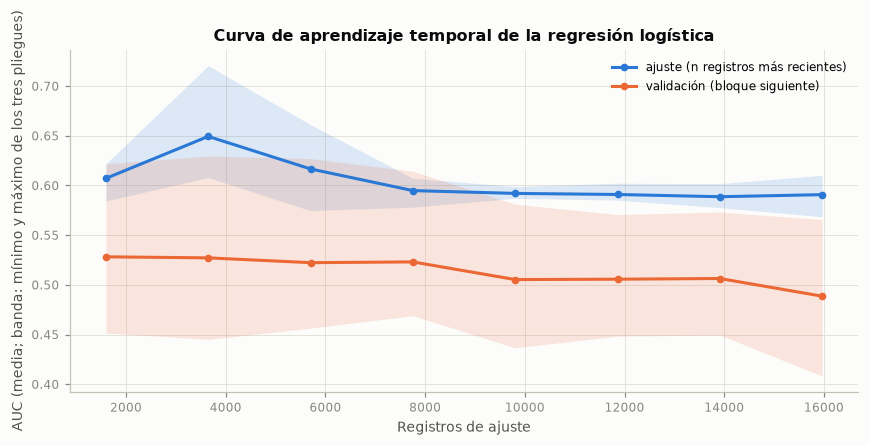

**Interpretación.** Con los 1 596 registros más recientes el AUC de validación promedio es 0,528 y con 15 963 es 0,489; el máximo (0,528) se alcanza con 1 596 registros. La brecha entre ajuste y validación pasa de 0,079 a 0,102.

En ese sentido, agregar historia más antigua mejora poco la predicción del bloque siguiente; incluso puede empeorarla, porque los periodos antiguos describen un contexto distinto. La brecha que persiste con todos los registros no es sobreajuste por tamaño de muestra sino deriva: el modelo describe bien el periodo con el que se ajusta y peor el siguiente.

En consecuencia, el tamaño de muestra es suficiente: las mejoras deben venir de adaptar el modelo al cambio de periodo (sección 4.7.1) y no de acumular más historia; la sección 4.11 evalúa si un modelo más flexible ayuda.

In [45]:
pliegues_lc = list(tss.split(X_tr))[-3:]
n_max = min(len(i_ent) for i_ent, _ in pliegues_lc)
tamanos = np.unique((np.linspace(0.1, 1.0, 8) * n_max).astype(int))
auc_ent = np.zeros((len(tamanos), len(pliegues_lc)))
auc_val = np.zeros_like(auc_ent)
for a, n_ in enumerate(tamanos):
    for b, (i_ent, i_val) in enumerate(pliegues_lc):
        sub = i_ent[-n_:]
        m_ = construir_modelo(C=C_opt).fit(X_tr.iloc[sub], y_tr.iloc[sub])
        auc_ent[a, b] = roc_auc_score(y_tr.iloc[sub], m_.predict_proba(X_tr.iloc[sub])[:, 1])
        auc_val[a, b] = roc_auc_score(y_tr.iloc[i_val], m_.predict_proba(X_tr.iloc[i_val])[:, 1])

fig, ax = plt.subplots(figsize=(8, 4))
for datos, col, etiqueta in [(auc_ent, AZUL, "ajuste (n registros más recientes)"), (auc_val, NARANJA, "validación (bloque siguiente)")]:
    ax.plot(tamanos, datos.mean(axis=1), color=col, marker="o", ms=4, label=etiqueta)
    ax.fill_between(tamanos, datos.min(axis=1), datos.max(axis=1), color=col, alpha=0.15, linewidth=0)
ax.set_xlabel("Registros de ajuste")
ax.set_ylabel("AUC (media; banda: mínimo y máximo de los tres pliegues)")
ax.set_title("Curva de aprendizaje temporal de la regresión logística")
ax.legend()
plt.tight_layout()
plt.show()

v_ini, v_fin = auc_val.mean(axis=1)[0], auc_val.mean(axis=1)[-1]
brecha_ini = auc_ent.mean(axis=1)[0] - v_ini
brecha_fin = auc_ent.mean(axis=1)[-1] - v_fin
interpretar(
    f"Con los {num(tamanos[0])} registros más recientes el AUC de validación promedio es {num(v_ini, 3)} y con "
    f"{num(tamanos[-1])} es {num(v_fin, 3)}; el máximo ({num(auc_val.mean(axis=1).max(), 3)}) se alcanza con "
    f"{num(tamanos[int(np.argmax(auc_val.mean(axis=1)))])} registros. La brecha entre ajuste y validación pasa de "
    f"{num(brecha_ini, 3)} a {num(brecha_fin, 3)}.",
    conectar('En ese sentido,', ("Agregar historia más antigua mejora poco la predicción del bloque siguiente"
     if v_fin - v_ini < 0.02 else "Agregar historia más antigua mejora la predicción del bloque siguiente")
    + ("; incluso puede empeorarla, porque los periodos antiguos describen un contexto distinto. "
       if v_fin < auc_val.mean(axis=1).max() - 0.01 else ". ")
    + "La brecha que persiste con todos los registros no es sobreajuste por tamaño de muestra sino deriva: el "
    "modelo describe bien el periodo con el que se ajusta y peor el siguiente."),
    conectar('En consecuencia,', "El tamaño de muestra es suficiente: las mejoras deben venir de adaptar el modelo al cambio de periodo "
    "(sección 4.7.1) y no de acumular más historia; la sección 4.11 evalúa si un modelo más flexible ayuda."))

## 4.9 Interpretación de los coeficientes

Los coeficientes son log-odds. Para las numéricas, el *odds ratio* (OR) corresponde al cambio de una desviación estándar en la variable transformada (después de `log1p` en `campaign` y `previous`); para las categóricas, compara cada categoría con la de referencia (la primera en orden alfabético). Un OR mayor que 1 aumenta las chances de suscribir y uno menor que 1 las reduce, **manteniendo constantes las demás variables**. Son asociaciones aprendidas con el periodo de entrenamiento, no efectos causales. Con la regularización elegida (sección 4.1) los coeficientes quedan encogidos hacia cero, así que los OR subestiman la magnitud de las asociaciones; la sección 4.9.1 mide su estabilidad.

Intercepto: -2,668 · columnas: 49 · C = 0,01


,Coeficiente,Odds ratio,Grupo
month = may (ref. apr),"-0,516","0,597",calendario
month = mar (ref. apr),"0,398","1,490",calendario
"month = infrecuente: dec, oct (ref. apr)","0,374","1,454",calendario
month = nov (ref. apr),"-0,291","0,747",calendario
nr.employed (+1 DE),"-0,263","0,768",macroeconómicas
cons.conf.idx (+1 DE),"-0,251","0,778",macroeconómicas
job = retired (ref. admin.),"0,232","1,262",atributos del cliente
default = unknown (ref. no),"-0,197","0,821",atributos del cliente
log1p(previous) (+1 DE),"-0,163","0,850",historial y campaña
job = student (ref. admin.),"0,158","1,172",atributos del cliente


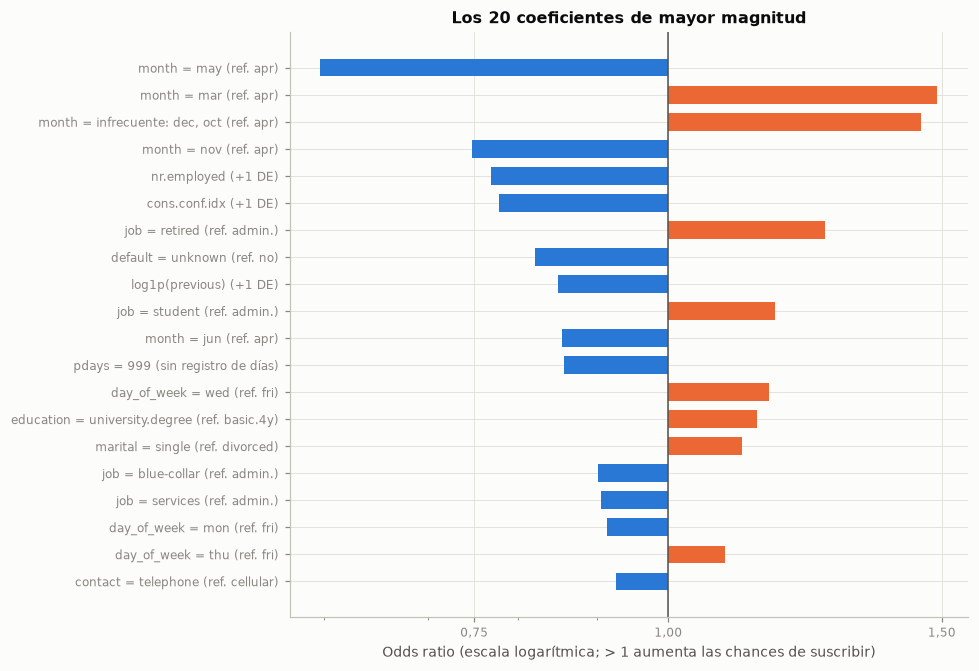

**Interpretación.** Los mayores aumentos de las chances corresponden a `month = mar (ref. apr)` (OR = 1,49); `month = infrecuente: dec, oct (ref. apr)` (OR = 1,45); `job = retired (ref. admin.)` (OR = 1,26). Las mayores reducciones, a `month = may (ref. apr)` (OR = 0,60); `month = nov (ref. apr)` (OR = 0,75); `nr.employed (+1 DE)` (OR = 0,77). Entre los 10 coeficientes más grandes hay 4 de calendario, 3 de atributos del cliente, 2 de macroeconómicas y 1 de historial y campaña.

Así mismo, los coeficientes de calendario y macroeconómicos describen el periodo de entrenamiento (sobre todo 2008): mezclan el efecto estacional con la tasa base de cada mes y no tienen por qué repetirse en periodos posteriores, lo que ayuda a explicar la caída de desempeño fuera del periodo de ajuste. La categoría infrecuente de `month` (dec y oct, con 77 registros en entrenamiento) tiene un OR de 1,45 estimado con muy pocos casos, y en prueba también recibe a los meses no vistos en entrenamiento (sep), así que ese efecto se extrapola a meses que el modelo nunca observó. Además, `housing = unknown` y `loan = unknown` son la misma información (sección 3.3.3), así que la penalización reparte su efecto entre ambas.

Por tal motivo, se opta por usar los odds ratios con signo estable (sección 4.9.1) para explicar el modelo, no para decidir intervenciones; la sección 4.9.2 evalúa si conviene reemplazar las variables de calendario por otras que se transfieran mejor entre periodos.

In [46]:
pre_f = modelo_final.named_steps["pre"]
lr_f = modelo_final.named_steps["lr"]
cod_f = pre_f.named_transformers_["cat"]
referencias = {c: cod_f.categories_[i][cod_f.drop_idx_[i]] for i, c in enumerate(VARS_CAT)}
infrec_f = {c: list(v) for c, v in zip(VARS_CAT, cod_f.infrequent_categories_) if v is not None}


def nombre_legible(n):
    bloque, var = n.split("__", 1)
    if bloque == "num":
        return f"{var} (+1 DE)"
    if bloque == "log":
        return f"log1p({var}) (+1 DE)"
    if bloque == "pdays":
        return "pdays = 999 (sin registro de días)" if var.startswith("missingindicator") else "pdays (+1 DE)"
    for c in sorted(VARS_CAT, key=len, reverse=True):
        if var.startswith(c + "_"):
            cat = var[len(c) + 1:]
            if cat == "infrequent_sklearn":
                cat = "infrecuente: " + ", ".join(infrec_f.get(c, []))
            return f"{c} = {cat} (ref. {referencias[c]})"
    return var


def grupo_coef(nombre):
    if nombre.startswith(("month", "day_of_week")):
        return "calendario"
    if nombre.startswith(("cons.", "nr.employed")):
        return "macroeconómicas"
    if nombre.startswith(("poutcome", "pdays", "log1p(previous)", "log1p(campaign)")):
        return "historial y campaña"
    if nombre.startswith("contact"):
        return "canal"
    return "atributos del cliente"


coefs = pd.DataFrame({"Coeficiente": lr_f.coef_[0]},
                     index=[nombre_legible(n) for n in pre_f.get_feature_names_out()])
coefs["Odds ratio"] = np.exp(coefs["Coeficiente"])
coefs["Grupo"] = [grupo_coef(i) for i in coefs.index]
coefs = coefs.reindex(coefs["Coeficiente"].abs().sort_values(ascending=False).index)
print(f"Intercepto: {num(lr_f.intercept_[0], 3)} · columnas: {len(coefs)} · C = {num_c(C_opt)}")
tabla(coefs.head(20), dec=3)

top = coefs.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.barh(top.index, top["Odds ratio"] - 1, left=1, color=[NARANJA if v > 1 else AZUL for v in top["Odds ratio"]],
        height=0.65)
ax.set_xscale("log")
marcas = [m for m in (0.1, 0.2, 0.3, 0.5, 0.75, 1, 1.5, 2, 3, 5, 10)
          if top["Odds ratio"].min() * 0.9 <= m <= top["Odds ratio"].max() * 1.1]
ax.set_xticks(marcas, [num(m, 2) for m in marcas])
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.axvline(1, color=TINTA_2, lw=1)
ax.set_xlabel("Odds ratio (escala logarítmica; > 1 aumenta las chances de suscribir)")
ax.set_title("Los 20 coeficientes de mayor magnitud")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

pos_ = coefs[coefs["Coeficiente"] > 0].head(3)
fila_inf_mes = [i for i in coefs.index if i.startswith("month = infrecuente")]
meses_no_vistos_te = [m for m in ORDEN_MESES if m in set(X_te["month"]) and m not in set(X_tr["month"])]
or_success = coefs.loc[[i for i in coefs.index if i.startswith("poutcome = success")], "Odds ratio"]
neg_ = coefs[coefs["Coeficiente"] < 0].head(3)
grupos_top = coefs.head(10)["Grupo"].value_counts()
interpretar(
    "Los mayores aumentos de las chances corresponden a "
    + "; ".join(f"`{i}` (OR = {num(r['Odds ratio'], 2)})" for i, r in pos_.iterrows())
    + ". Las mayores reducciones, a "
    + "; ".join(f"`{i}` (OR = {num(r['Odds ratio'], 2)})" for i, r in neg_.iterrows())
    + ". Entre los 10 coeficientes más grandes hay "
    + enumerar([f"{v} de {k}" for k, v in grupos_top.items()], codigo=False) + ".",
    conectar('Así mismo,', "Los coeficientes de calendario y macroeconómicos describen el periodo de entrenamiento (sobre todo 2008): "
    "mezclan el efecto estacional con la tasa base de cada mes y no tienen por qué repetirse en periodos "
    "posteriores, lo que ayuda a explicar la caída de desempeño fuera del periodo de ajuste. "
    + (f"La categoría infrecuente de `month` ({enumerar(infrec_f.get('month', []), codigo=False)}, con "
       f"{num(int(X_tr['month'].isin(infrec_f.get('month', [])).sum()))} registros en entrenamiento) tiene un OR de "
       f"{num(coefs.loc[fila_inf_mes[0], 'Odds ratio'], 2)} estimado con muy pocos casos"
       + (f", y en prueba también recibe a los meses no vistos en entrenamiento ({enumerar(meses_no_vistos_te, codigo=False)}), "
          "así que ese efecto se extrapola a meses que el modelo nunca observó. " if meses_no_vistos_te else ". ")
       if fila_inf_mes else "")
    + (f"Algunos signos son contraintuitivos, como `poutcome = success` con OR de {num(or_success.iloc[0], 2)} frente "
       "a `failure`: `poutcome`, `pdays` y `previous` están ligadas por construcción (sección 3.3.2) y el modelo "
       "reparte entre ellas el efecto del historial, así que el signo de cada una por separado no es interpretable. "
       if len(or_success) and or_success.iloc[0] < 1 else "")
    + "Además, `housing = unknown` y `loan = unknown` son la misma información (sección 3.3.3), así que la "
    "penalización reparte su efecto entre ambas."),
    conectar('Por tal motivo, se opta por', "Usar los odds ratios con signo estable (sección 4.9.1) para explicar el modelo, no para decidir "
    "intervenciones; la sección 4.9.2 evalúa si conviene reemplazar las variables de calendario por otras que se "
    "transfieran mejor entre periodos."))

### 4.9.1 Estabilidad de los coeficientes según `C`

Para medir la inestabilidad de los coeficientes se reajusta la regresión logística en 100 remuestras *bootstrap* por bloques de día del entrenamiento, con el preprocesamiento fijo, para cada valor de `C` de la rejilla. La desviación de cada coeficiente entre remuestras mide cuánto depende de la muestra; un intervalo que cruza el cero indica que ni siquiera su signo está determinado. Se comparan el `C` elegido (sección 4.1) y el que maximiza el AUC de validación.

,Log-loss validación,AUC validación,Norma L2 de los coeficientes,Desv. bootstrap media,Desv. bootstrap máxima
C,,,,,
"0,001","0,261","0,506","0,426","0,016","0,047"
"0,01","0,251","0,514","1,051","0,053","0,151"
"0,1","0,318","0,522","2,472","0,112","0,293"
1,"0,467","0,537","3,392","0,172","0,666"
10,"0,489","0,542","3,753","0,218","0,868"
100,"0,495","0,542","3,788","0,250","1,192"


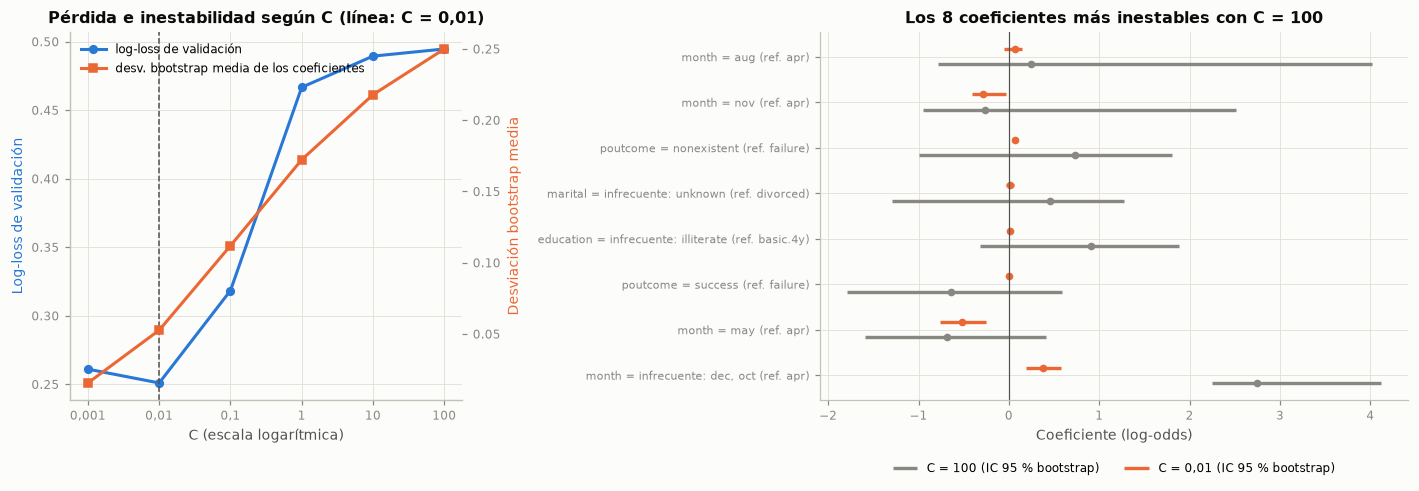

**Coeficientes del modelo final (C = 0,01) con IC 95 % bootstrap por bloques de día; se muestran los 15 de mayor magnitud**

,Coeficiente,IC 95 % inferior,IC 95 % superior,Signo estable
month = may (ref. apr),"-0,516","-0,757","-0,248",sí
month = mar (ref. apr),"0,398","0,217","0,535",sí
"month = infrecuente: dec, oct (ref. apr)","0,374","0,185","0,582",sí
month = nov (ref. apr),"-0,291","-0,405","-0,031",sí
nr.employed (+1 DE),"-0,263","-0,464","-0,123",sí
cons.conf.idx (+1 DE),"-0,251","-0,351","-0,174",sí
job = retired (ref. admin.),"0,232","0,119","0,327",sí
default = unknown (ref. no),"-0,197","-0,298","-0,099",sí
log1p(previous) (+1 DE),"-0,163","-0,197","-0,125",sí
job = student (ref. admin.),"0,158","0,074","0,231",sí


**Interpretación.** Con C = 100 la desviación bootstrap media de los coeficientes es 0,250 y la máxima 1,192, en `month = aug (ref. apr)`, que cambia de signo en el 68 % de las remuestras; con C = 0,01 bajan a 0,053 y 0,151. De los 8 coeficientes más inestables, el intervalo cruza el cero en 7 con C = 100 y en 4 con C = 0,01. Las dummies de `month` reproducen buena parte de las macro (R² de 0,70 en cons.price.idx, 0,63 en cons.conf.idx y 0,76 en nr.employed). En el modelo final, 14 de los 15 coeficientes de mayor magnitud tienen un signo estable.

Lo anterior indica que la inestabilidad con poca regularización no es ruido de muestreo cualquiera: viene de variables que dicen casi lo mismo (`month` y las macro, que dentro de entrenamiento solo distinguen meses; `poutcome`, `pdays` y `previous`, ligadas por construcción) y de categorías con pocos casos. Sin penalización, el modelo reparte el efecto entre ellas de forma arbitraria y cada remuestra lo reparte distinto; esos coeficientes grandes son los que se extrapolan mal a un periodo nuevo (sección 4.1). La regularización reduce esa varianza a cambio de encoger los coeficientes hacia cero, y aquí ese sesgo cuesta poco AUC de validación.

De ahí que se opte por mantener C = 0,01 e interpretar en la sección 4.9 solo los coeficientes con signo estable; los modelos más flexibles de la sección 4.11 se eligen con el mismo criterio de pérdida logarítmica.

In [47]:
from sklearn.linear_model import LinearRegression

Z_tr = pre_f.transform(X_tr)                 # preprocesamiento fijo: solo se reajusta la regresión
nombres_z = [nombre_legible(n) for n in pre_f.get_feature_names_out()]
_, g_dia_tr = np.unique(dia_tr.to_numpy(), return_inverse=True)
bloques_tr = [np.flatnonzero(g_dia_tr == g) for g in range(g_dia_tr.max() + 1)]
B_COEF = 100
rng_coef = np.random.default_rng(SEED)
remuestras_tr = [np.concatenate([bloques_tr[g] for g in rng_coef.integers(0, len(bloques_tr), size=len(bloques_tr))])
                 for _ in range(B_COEF)]
valores_C = sorted(res_grid["param_lr__C"].astype(float))
coef_completo, coef_boot = {}, {}
for C_ in valores_C:
    coef_completo[C_] = LogisticRegression(C=C_, max_iter=5000).fit(Z_tr, y_tr).coef_[0]
    coef_boot[C_] = np.array([LogisticRegression(C=C_, max_iter=5000).fit(Z_tr[ii], y_tr.iloc[ii]).coef_[0]
                              for ii in remuestras_tr])

ll_por_C = dict(zip(res_grid["param_lr__C"].astype(float), -res_grid["mean_test_logloss"]))
auc_por_C = dict(zip(res_grid["param_lr__C"].astype(float), res_grid["mean_test_auc"]))
estabilidad = pd.DataFrame({
    "C": [num_c(c) for c in valores_C],
    "Log-loss validación": [ll_por_C[c] for c in valores_C],
    "AUC validación": [auc_por_C[c] for c in valores_C],
    "Norma L2 de los coeficientes": [np.linalg.norm(coef_completo[c]) for c in valores_C],
    "Desv. bootstrap media": [coef_boot[c].std(axis=0).mean() for c in valores_C],
    "Desv. bootstrap máxima": [coef_boot[c].std(axis=0).max() for c in valores_C]}).set_index("C")
tabla(estabilidad, dec=3)

# Colinealidad que explica la inestabilidad: cuánto de cada macro reproducen las dummies de month
cols_mes = [j for j, n in enumerate(nombres_z) if n.startswith("month")]
r2_mes = {n.split(" (")[0]: LinearRegression().fit(Z_tr[:, cols_mes], Z_tr[:, j]).score(Z_tr[:, cols_mes], Z_tr[:, j])
          for j, n in enumerate(nombres_z) if n.startswith(("cons.", "nr.employed", "emp.var", "euribor"))}

sd_auc = coef_boot[C_auc].std(axis=0)
inestables = np.argsort(sd_auc)[::-1][:8]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
lx = np.log10(valores_C)
axs[0].plot(lx, estabilidad["Log-loss validación"], color=AZUL, marker="o", ms=5, label="log-loss de validación")
ax0b = axs[0].twinx()
ax0b.plot(lx, estabilidad["Desv. bootstrap media"], color=NARANJA, marker="s", ms=5,
          label="desv. bootstrap media de los coeficientes")
ax0b.grid(False)
axs[0].axvline(np.log10(C_opt), color=TINTA_2, ls="--", lw=1)
axs[0].set_xticks(lx, [num_c(c) for c in valores_C])
axs[0].set_xlabel("C (escala logarítmica)")
axs[0].set_ylabel("Log-loss de validación", color=AZUL)
ax0b.set_ylabel("Desviación bootstrap media", color=NARANJA)
axs[0].set_title(f"Pérdida e inestabilidad según C (línea: C = {num_c(C_opt)})")
h1, l1 = axs[0].get_legend_handles_labels()
h2, l2 = ax0b.get_legend_handles_labels()
axs[0].legend(h1 + h2, l1 + l2, loc="upper left")
for C_, color_, desfase_ in [(C_auc, GRIS, 0.17), (C_opt, NARANJA, -0.17)]:
    lo_c, hi_c = np.percentile(coef_boot[C_][:, inestables], [2.5, 97.5], axis=0)
    y_c = np.arange(len(inestables)) + desfase_
    axs[1].hlines(y_c, lo_c, hi_c, color=color_, lw=2.2, label=f"C = {num_c(C_)} (IC 95 % bootstrap)")
    axs[1].plot(coef_completo[C_][inestables], y_c, "o", color=color_, ms=4)
axs[1].axvline(0, color=TINTA_2, lw=0.8)
axs[1].set_yticks(np.arange(len(inestables)), [nombres_z[j] for j in inestables], fontsize=7.5)
axs[1].invert_yaxis()
axs[1].set_xlabel("Coeficiente (log-odds)")
axs[1].set_title(f"Los 8 coeficientes más inestables con C = {num_c(C_auc)}")
axs[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
plt.tight_layout()
plt.show()

lo_o, hi_o = np.percentile(coef_boot[C_opt], [2.5, 97.5], axis=0)
signo_estable = (lo_o > 0) | (hi_o < 0)
coef_ic = pd.DataFrame({"Coeficiente": coef_completo[C_opt], "IC 95 % inferior": lo_o, "IC 95 % superior": hi_o,
                        "Signo estable": np.where(signo_estable, "sí", "no")}, index=nombres_z)
coef_ic = coef_ic.reindex(coef_ic["Coeficiente"].abs().sort_values(ascending=False).index)
display(Markdown(f"**Coeficientes del modelo final (C = {num_c(C_opt)}) con IC 95 % bootstrap por bloques de día; "
                 "se muestran los 15 de mayor magnitud**"))
tabla(coef_ic.head(15), dec=3)

j_max = inestables[0]
cambia_signo = (np.sign(coef_boot[C_auc][:, j_max]) != np.sign(coef_completo[C_auc][j_max])).mean()
cruzan = {C_: int(((np.percentile(coef_boot[C_][:, inestables], 2.5, axis=0) < 0) &
                   (np.percentile(coef_boot[C_][:, inestables], 97.5, axis=0) > 0)).sum()) for C_ in (C_auc, C_opt)}
r2_txt = enumerar([f"{num(v, 2)} en {k}" for k, v in r2_mes.items()], codigo=False)
interpretar(
    f"Con C = {num_c(C_auc)} la desviación bootstrap media de los coeficientes es "
    f"{num(estabilidad.loc[num_c(C_auc), 'Desv. bootstrap media'], 3)} y la máxima "
    f"{num(estabilidad.loc[num_c(C_auc), 'Desv. bootstrap máxima'], 3)}, en `{nombres_z[j_max]}`, que cambia de signo en "
    f"el {pct(cambia_signo, 0)} de las remuestras; con C = {num_c(C_opt)} bajan a "
    f"{num(estabilidad.loc[num_c(C_opt), 'Desv. bootstrap media'], 3)} y "
    f"{num(estabilidad.loc[num_c(C_opt), 'Desv. bootstrap máxima'], 3)}. De los 8 coeficientes más inestables, el "
    f"intervalo cruza el cero en {cruzan[C_auc]} con C = {num_c(C_auc)} y en {cruzan[C_opt]} con C = {num_c(C_opt)}. Las "
    f"dummies de `month` reproducen buena parte de las macro (R² de {r2_txt}). En el modelo final, "
    f"{int(signo_estable[np.argsort(-np.abs(coef_completo[C_opt]))[:15]].sum())} de los 15 coeficientes de mayor "
    "magnitud tienen un signo estable.",
    conectar('Lo anterior indica que', "La inestabilidad con poca regularización no es ruido de muestreo cualquiera: viene de variables que dicen casi "
    "lo mismo (`month` y las macro, que dentro de entrenamiento solo distinguen meses; `poutcome`, `pdays` y "
    "`previous`, ligadas por construcción) y de categorías con pocos casos. Sin penalización, el modelo reparte el "
    "efecto entre ellas de forma arbitraria y cada remuestra lo reparte distinto; esos coeficientes grandes son los "
    "que se extrapolan mal a un periodo nuevo (sección 4.1). La regularización reduce esa varianza a cambio de "
    "encoger los coeficientes hacia cero, y aquí ese sesgo cuesta poco AUC de validación."),
    conectar('De ahí que se opte por', f"Mantener C = {num_c(C_opt)} e interpretar en la sección 4.9 solo los coeficientes con signo estable; los "
    "modelos más flexibles de la sección 4.11 se eligen con el mismo criterio de pérdida logarítmica."))


### 4.9.2 ¿Conviene reemplazar las variables de calendario?

Los coeficientes de `month` describen la tasa base de cada mes del entrenamiento (sección 4.9) y son los más inestables (sección 4.9.1). Se evalúan dos alternativas con la misma validación temporal y la misma rejilla de `C`: codificar el mes con **componentes cíclicos** (seno y coseno del número de mes, la forma que sugiere el enunciado para las variables de calendario y que además da un valor a los meses no vistos) y **retirar** `month`. Para cada variante, `C` se elige por la pérdida logarítmica.

In [48]:
MES_NUM = {m: i + 1 for i, m in enumerate(ORDEN_MESES)}


def mes_ciclico(X):
    """Seno y coseno del número de mes: un ciclo anual continuo en el que diciembre queda junto a enero."""
    num_mes = np.array([MES_NUM[v] for v in np.asarray(X).ravel()], dtype=float)
    return np.c_[np.sin(2 * np.pi * num_mes / 12), np.cos(2 * np.pi * num_mes / 12)]


VARIANTES_CAL = ["month en one-hot (modelo base)", "month cíclico (seno y coseno)", "sin month"]


def modelo_calendario(variante, C=1.0):
    categoricas = VARS_CAT if variante == VARIANTES_CAL[0] else [c for c in VARS_CAT if c != "month"]
    pre = construir_preprocesador(VARS_NUM, categoricas)
    if variante == VARIANTES_CAL[1]:
        pre.transformers.append(("mes", FunctionTransformer(mes_ciclico, feature_names_out=lambda t, n: ["month_sin",
                                                                                                         "month_cos"]),
                                 ["month"]))
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=C, max_iter=5000))])


ultimo = tss.n_splits - 1
filas_cal = []
for v in VARIANTES_CAL:
    g_cal = GridSearchCV(modelo_calendario(v), {"lr__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}, cv=tss,
                         scoring={"logloss": "neg_log_loss", "auc": "roc_auc"}, refit="logloss").fit(X_tr, y_tr)
    r_cal, i_cal = g_cal.cv_results_, g_cal.best_index_
    filas_cal.append({"Variante": v, "C elegido": num_c(g_cal.best_params_["lr__C"]),
                      "Log-loss validación": -r_cal["mean_test_logloss"][i_cal],
                      "AUC validación": r_cal["mean_test_auc"][i_cal],
                      "Log-loss último pliegue": -r_cal[f"split{ultimo}_test_logloss"][i_cal],
                      "AUC último pliegue": r_cal[f"split{ultimo}_test_auc"][i_cal]})
calendario = pd.DataFrame(filas_cal).set_index("Variante")
tabla(calendario, dec=4)

base_es_mejor = calendario["Log-loss validación"].idxmin() == VARIANTES_CAL[0]
interpretar(
    "La pérdida logarítmica de validación, con el C que mejor le sirve a cada variante, es de "
    + enumerar([f"{num(r['Log-loss validación'], 4)} para «{v}» (AUC de {num(r['AUC validación'], 3)})"
                for v, r in calendario.iterrows()], codigo=False)
    + ". En el último pliegue, el único que valida con meses de 2009, el AUC es de "
    + enumerar([f"{num(r['AUC último pliegue'], 3)} para «{v}»" for v, r in calendario.iterrows()], codigo=False)
    + ".",
    (conectar('Esto significa que', "Ni el ciclo anual continuo ni retirar el mes mejoran al modelo base. En entrenamiento, el mes no describe una "
     "estacionalidad que se repita, sino la tasa base de cada periodo (sección 3.6.4), y el seno y el coseno imponen "
     "una forma suave que esos datos no tienen; sin `month`, el modelo pierde la señal que permite ordenar los meses "
     "de 2009." if base_es_mejor else
     f"La variante «{calendario['Log-loss validación'].idxmin()}» tiene menor pérdida de validación que la codificación "
     "del modelo base, así que el mes se transfiere mejor entre periodos con esa representación.")),
    (conectar('En consecuencia, se decide', f"Mantener `month` en one-hot con C = {num_c(C_opt)}: es la variante con menor pérdida de validación, y su "
     "inestabilidad queda controlada por la regularización (sección 4.9.1)." if base_es_mejor else
     f"Adoptar la variante «{calendario['Log-loss validación'].idxmin()}» en el modelo base.")))


,C elegido,Log-loss validación,AUC validación,Log-loss último pliegue,AUC último pliegue
Variante,,,,,
month en one-hot (modelo base),"0,01","0,2510","0,5139","0,4140","0,6774"
month cíclico (seno y coseno),"0,1","0,2586","0,4756","0,4455","0,4714"
sin month,"0,001","0,2623","0,4983","0,4716","0,6074"


**Interpretación.** La pérdida logarítmica de validación, con el C que mejor le sirve a cada variante, es de 0,2510 para «month en one-hot (modelo base)» (AUC de 0,514), 0,2586 para «month cíclico (seno y coseno)» (AUC de 0,476) y 0,2623 para «sin month» (AUC de 0,498). En el último pliegue, el único que valida con meses de 2009, el AUC es de 0,677 para «month en one-hot (modelo base)», 0,471 para «month cíclico (seno y coseno)» y 0,607 para «sin month».

Esto significa que ni el ciclo anual continuo ni retirar el mes mejoran al modelo base. En entrenamiento, el mes no describe una estacionalidad que se repita, sino la tasa base de cada periodo (sección 3.6.4), y el seno y el coseno imponen una forma suave que esos datos no tienen; sin `month`, el modelo pierde la señal que permite ordenar los meses de 2009.

En consecuencia, se decide mantener `month` en one-hot con C = 0,01: es la variante con menor pérdida de validación, y su inestabilidad queda controlada por la regularización (sección 4.9.1).

## 4.10 Diagnóstico temporal: contraste con la validación aleatoria, desempeño por año y residuos

El enunciado pide comprobar que la validación respete la estructura de los datos y revisar la dependencia de los residuos. Se compara la validación temporal del modelo final con la que habría dado una validación estratificada aleatoria sobre el mismo entrenamiento (contraste), se mide el desempeño en prueba por año y se calcula la autocorrelación de los residuos de Pearson en prueba, en el orden temporal de las filas.

,AUC,AUC-PR
Validación temporal en entrenamiento (esquema usado),"0,514","0,097"
Validación aleatoria estratificada en entrenamiento (contraste),"0,667","0,190"
Prueba cronológica,"0,710","0,548"


,Registros,Prevalencia,Probabilidad media predicha,AUC,AUC-PR
Año (prueba),,,,,
2009,6 178,"0,237","0,127","0,656","0,422"
2010,2 058,"0,521","0,287","0,663","0,666"


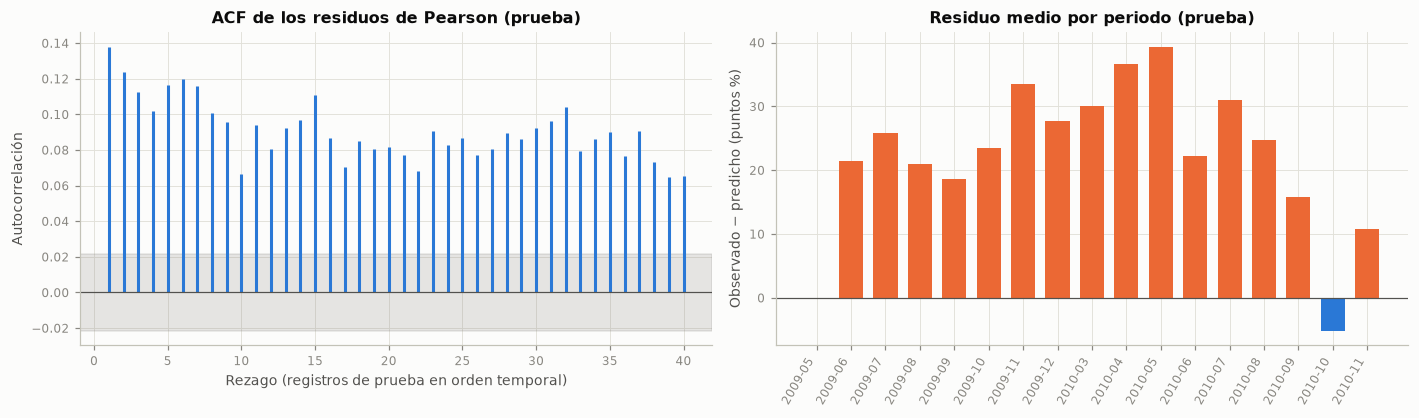

Ljung-Box: Q(10) = 1 010,3 (p < 0,001); Q(40) = 2 810,3 (p < 0,001)


**Interpretación.** Si se hubiera validado de forma aleatoria, el AUC estimado en entrenamiento sería de 0,667, frente a 0,514 de la validación temporal; en la prueba cronológica el AUC es 0,710. Por año, en prueba: 2009: 6 178 registros, prevalencia 0,237, probabilidad media predicha 0,127 y AUC 0,656; 2010: 2 058 registros, prevalencia 0,521, probabilidad media predicha 0,287 y AUC 0,663. El residuo medio supera los 5 puntos porcentuales en 15 de los 17 periodos de prueba; en los meses que el modelo trata como infrecuentes o no vio en entrenamiento (sep, oct y dec; 1 392 registros de prueba) el residuo medio es de 17,2 puntos, frente a 13,5 en los demás. Los residuos tienen 40 de 40 rezagos fuera de la banda del 95 % y la prueba de Ljung-Box rechaza la ausencia de autocorrelación hasta el rezago 40 (p < 0,001).

Por consiguiente, la validación aleatoria habría sobrestimado la capacidad del modelo para el periodo siguiente, lo que confirma que respetar el orden temporal era necesario. El AUC global de prueba (0,710) es mayor que el de cada año por separado (0,656 y 0,663): una parte viene de ordenar bien entre periodos, porque el modelo asigna probabilidades más altas al año con mayor tasa de suscripción, extrapolando el contexto a partir de las macro y del mes, y no solo de distinguir clientes dentro de un mismo periodo. Aun así, el AUC de prueba supera al de la validación temporal, dominada por bloques de 2008 con muy poca señal: el desempeño depende del periodo evaluado y una sola cifra no lo resume. Los residuos medios por periodo y su autocorrelación muestran que el error cambia de un periodo a otro: hay información temporal, como la tasa base de cada periodo, que el modelo no captura.

Por lo anterior, conviene mantener la validación temporal como esquema principal y adaptar la tasa base con la recalibración mensual del intercepto (sección 4.7.1), que solo usa meses ya cerrados.

In [49]:
cv_contraste = cross_validate(construir_modelo(C=C_opt), X_tr, y_tr, cv=skf, scoring=["roc_auc", "average_precision"])
contraste = pd.DataFrame({
    "AUC": [auc_val_opt, cv_contraste["test_roc_auc"].mean(), P[nombre_u]["AUC"]],
    "AUC-PR": [res_grid.loc[i_opt, "mean_test_auc_pr"], cv_contraste["test_average_precision"].mean(),
               P[nombre_u]["AUC-PR"]]},
    index=["Validación temporal en entrenamiento (esquema usado)",
           "Validación aleatoria estratificada en entrenamiento (contraste)", "Prueba cronológica"])
tabla(contraste, dec=3)

mask_anio = {a: (anio_te == a).to_numpy() for a in sorted(anio_te.unique())}
por_anio_te = pd.DataFrame({
    a: {"Registros": int(m.sum()), "Prevalencia": yv[m].mean(), "Probabilidad media predicha": prob_te[m].mean(),
        "AUC": roc_auc_score(yv[m], prob_te[m]), "AUC-PR": average_precision_score(yv[m], prob_te[m])}
    for a, m in mask_anio.items()}).T.rename_axis("Año (prueba)")
por_anio_te["Registros"] = por_anio_te["Registros"].astype(int)
tabla(por_anio_te, dec=3)

resid = (yv - prob_te) / np.sqrt(prob_te * (1 - prob_te))   # X_te ya está en orden temporal
acf_res = acf(resid, nlags=40, fft=True)
lb = acorr_ljungbox(resid, lags=[10, 40])
banda = 1.96 / np.sqrt(len(resid))
res_periodo = pd.Series(yv - prob_te).groupby(periodo_te.to_numpy()).mean()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
axs[0].vlines(range(1, 41), 0, acf_res[1:], color=AZUL, lw=2)
axs[0].axhspan(-banda, banda, color=GRIS, alpha=0.2)
axs[0].axhline(0, color=TINTA_2, lw=0.8)
axs[0].set_xlabel("Rezago (registros de prueba en orden temporal)")
axs[0].set_ylabel("Autocorrelación")
axs[0].set_title("ACF de los residuos de Pearson (prueba)")
xp = np.arange(len(res_periodo))
axs[1].bar(xp, 100 * res_periodo.values, color=[NARANJA if v > 0 else AZUL for v in res_periodo.values], width=0.7)
axs[1].axhline(0, color=TINTA_2, lw=0.8)
axs[1].set_xticks(xp, res_periodo.index, rotation=60, ha="right")
axs[1].set_ylabel("Observado − predicho (puntos %)")
axs[1].set_title("Residuo medio por periodo (prueba)")
plt.tight_layout()
plt.show()
print(f"Ljung-Box: Q(10) = {num(lb['lb_stat'].iloc[0], 1)} ({p_txt(lb['lb_pvalue'].iloc[0])}); "
      f"Q(40) = {num(lb['lb_stat'].iloc[1], 1)} ({p_txt(lb['lb_pvalue'].iloc[1])})")

auc_cv_alea = cv_contraste["test_roc_auc"].mean()
meses_extrap = [m for m in ORDEN_MESES if m in set(infrec_f.get("month", [])) | set(meses_no_vistos_te)]
m_ext = X_te["month"].isin(meses_extrap).to_numpy()
res_ext = (yv - prob_te)[m_ext].mean() if m_ext.any() else np.nan
res_resto = (yv - prob_te)[~m_ext].mean()
sig_acf = int((np.abs(acf_res[1:]) > banda).sum())
periodos_sub = int((res_periodo > 0.05).sum())
interpretar(
    f"Si se hubiera validado de forma aleatoria, el AUC estimado en entrenamiento sería de {num(auc_cv_alea, 3)}, "
    f"frente a {num(auc_val_opt, 3)} de la validación temporal; en la prueba cronológica el AUC es "
    f"{num(P[nombre_u]['AUC'], 3)}. Por año, en prueba: "
    + "; ".join(f"{a}: {num(int(r['Registros']))} registros, prevalencia {num(r['Prevalencia'], 3)}, probabilidad media "
                f"predicha {num(r['Probabilidad media predicha'], 3)} y AUC {num(r['AUC'], 3)}"
                for a, r in por_anio_te.iterrows())
    + f". El residuo medio supera los 5 puntos porcentuales en {periodos_sub} de los {len(res_periodo)} periodos de "
    "prueba"
    + (f"; en los meses que el modelo trata como infrecuentes o no vio en entrenamiento ({enumerar(meses_extrap, codigo=False)}; "
       f"{num(int(m_ext.sum()))} registros de prueba) el residuo medio es de {num(100 * res_ext, 1)} puntos, frente a "
       f"{num(100 * res_resto, 1)} en los demás" if m_ext.any() else "")
    + f". Los residuos tienen {sig_acf} de 40 rezagos fuera de la banda del 95 % y la prueba de Ljung-Box "
    f"{'rechaza' if lb['lb_pvalue'].iloc[1] < 0.05 else 'no rechaza'} la ausencia de autocorrelación hasta el rezago 40 "
    f"({p_txt(lb['lb_pvalue'].iloc[1])}).",
    conectar('Por consiguiente,', ("La validación aleatoria habría sobrestimado la capacidad del modelo para el periodo siguiente, lo que confirma "
     "que respetar el orden temporal era necesario. " if auc_cv_alea > auc_val_opt + 0.05 else "")
    + (f"El AUC global de prueba ({num(P[nombre_u]['AUC'], 3)}) es mayor que el de cada año por separado "
       f"({enumerar([num(v, 3) for v in por_anio_te['AUC']], codigo=False)}): una parte viene de ordenar bien entre "
       "periodos, porque el modelo asigna probabilidades más altas al año con mayor tasa de suscripción, extrapolando "
       "el contexto a partir de las macro y del mes, y no solo de distinguir clientes dentro de un mismo periodo. "
       if (por_anio_te["AUC"] < P[nombre_u]["AUC"] - 0.03).all() else "")
    + ("Aun así, el AUC de prueba supera al de la validación temporal, dominada por bloques de 2008 con muy poca "
       "señal: el desempeño depende del periodo evaluado y una sola cifra no lo resume. "
       if P[nombre_u]["AUC"] > auc_val_opt + 0.05 else "")
    + ("La sobrestimación en los meses infrecuentes o no vistos proviene del coeficiente de la categoría infrecuente "
       "de `month` (sección 4.9), estimado con muy pocos casos de 2008 y extrapolado a otros meses. "
       if m_ext.any() and res_ext < -0.05 else "")
    + "Los residuos medios por periodo y su autocorrelación muestran que el error cambia de un periodo a otro: hay "
    "información temporal, como la tasa base de cada periodo, que el modelo no captura."),
    conectar('Por lo anterior, conviene', "Mantener la validación temporal como esquema principal y adaptar la tasa base con la recalibración mensual "
    "del intercepto (sección 4.7.1), que solo usa meses ya cerrados."))

## 4.11 Comparación con modelos más flexibles

Para saber si una forma funcional más flexible mejora al modelo base, se comparan tres alternativas en **las mismas condiciones**: la misma partición y validación temporal, la misma regla para elegir hiperparámetros (pérdida logarítmica), la misma recalibración mensual del intercepto, el umbral elegido de la misma forma (sección 4.7.1) y los mismos intervalos *bootstrap* pareados por bloques de día.

- **Regresión logística con splines:** el modelo base con *splines* cúbicos para la edad y para `log1p(campaign)` (Hastie et al., 2009), que permiten relaciones no lineales sin perder la forma logística.
- **Bosque aleatorio** (Breiman, 2001): 300 árboles sobre el preprocesamiento del modelo base; se ajustan el tamaño mínimo de las hojas y el número de variables por división.
- **Gradient boosting** (Friedman, 2001), con `HistGradientBoostingClassifier`: árboles secuenciales con soporte nativo para las categóricas; se ajustan el número de iteraciones, el de hojas y el tamaño mínimo de las hojas, con tasa de aprendizaje 0,05 y penalización L2.

Además del AUC global se reporta el **AUC dentro de cada mes** (promedio ponderado por registros), que mide cuán bien ordena cada modelo a los clientes de un mismo periodo, sin el efecto de la tasa base. Los intervalos de la figura son los de cada modelo por separado; la comparación entre modelos se lee en la tabla de diferencias pareadas, que es más precisa.

**Validación temporal (entrenamiento), con los hiperparámetros elegidos por pérdida logarítmica**

,Hiperparámetros elegidos,Log-loss validación,AUC validación,AUC-PR validación,AUC último pliegue
Modelo,,,,,
Regresión logística (modelo base),"C = 0,01","0,2510","0,5139","0,0968","0,6774"
Logística con splines,"C = 0,01","0,2504","0,5199","0,0992","0,6824"
Bosque aleatorio,"max_features = sqrt, min_samples_leaf = 20","0,2474","0,5174","0,0870","0,6681"
Gradient boosting,"max_iter = 25, max_leaf_nodes = 15, min_samples_leaf = 500","0,2621","0,5143","0,0895","0,6496"


**Prueba con recalibración mensual: valor puntual [IC 95 % bootstrap por bloques de día]**

,Umbral,AUC sin recalibrar,AUC,AUC-PR,Brier,F1,Precision,Recall,AUC dentro de cada mes
Regresión logística (modelo base),"0,13","0,710","0,752 [0,697; 0,776]","0,580 [0,540; 0,621]","0,178 [0,151; 0,215]","0,563 [0,524; 0,602]","0,421 [0,391; 0,454]","0,849 [0,782; 0,910]","0,625"
Logística con splines,"0,13","0,713","0,751 [0,697; 0,775]","0,579 [0,538; 0,618]","0,178 [0,152; 0,215]","0,559 [0,517; 0,602]","0,415 [0,382; 0,452]","0,854 [0,790; 0,916]","0,622"
Bosque aleatorio,"0,21","0,716","0,735 [0,661; 0,765]","0,519 [0,483; 0,555]","0,186 [0,157; 0,225]","0,581 [0,550; 0,612]","0,460 [0,438; 0,486]","0,788 [0,705; 0,870]","0,607"
Gradient boosting,"0,01","0,507","0,697 [0,620; 0,734]","0,470 [0,436; 0,506]","0,203 [0,170; 0,248]","0,471 [0,400; 0,561]","0,308 [0,250; 0,389]","1,000 [1,000; 1,000]","0,557"


**Diferencia frente al modelo base (flexible − base) [IC 95 % bootstrap pareado por bloques de día]**

,AUC,AUC-PR,Brier,F1
Logística con splines,"-0,001 [-0,002; 0,001]","-0,002 [-0,004; 0,001]","0,000 [-0,000; 0,000]","-0,004 [-0,012; 0,003]"
Bosque aleatorio,"-0,017 [-0,040; -0,003]","-0,062 [-0,082; -0,041]","0,008 [0,005; 0,012]","0,019 [0,002; 0,036]"
Gradient boosting,"-0,055 [-0,082; -0,036]","-0,110 [-0,132; -0,089]","0,025 [0,017; 0,035]","-0,091 [-0,131; -0,033]"


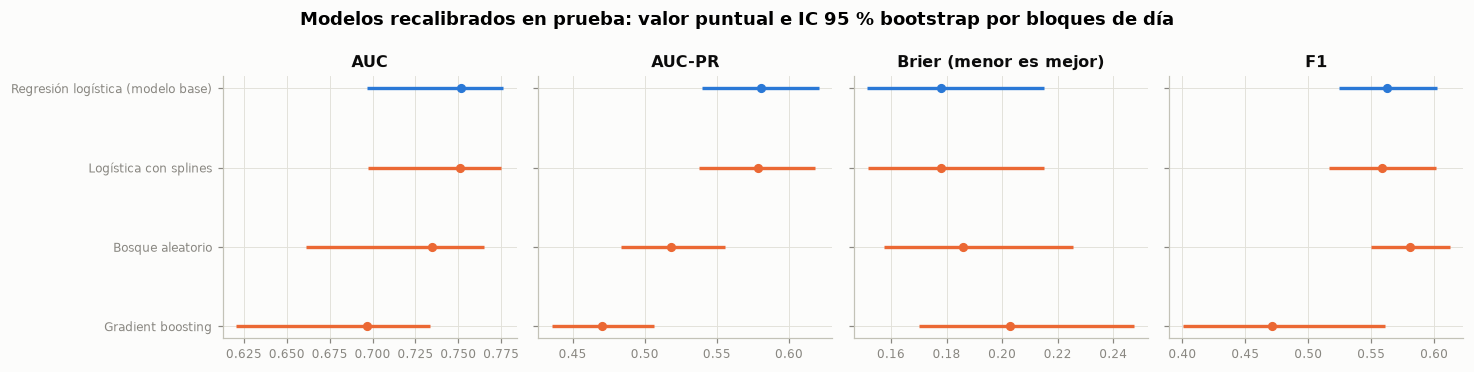

**Interpretación.** En validación, la pérdida logarítmica va de 0,2474 (bosque aleatorio) a 0,2621 (gradient boosting). En prueba, con la misma recalibración, el AUC es de 0,752 (modelo base), 0,751 (logística con splines), 0,735 (bosque aleatorio) y 0,697 (gradient boosting); el Brier, de 0,178, 0,178, 0,186 y 0,203 en el mismo orden. Frente al modelo base, en diferencias pareadas: logística con splines, AUC -0,001 [-0,002; 0,001], AUC-PR -0,002, Brier 0,000 y F1 -0,004 [-0,012; 0,003]; bosque aleatorio, AUC -0,017 [-0,040; -0,003], AUC-PR -0,062, Brier 0,008 y F1 0,019 [0,002; 0,036]; gradient boosting, AUC -0,055 [-0,082; -0,036], AUC-PR -0,110, Brier 0,025 y F1 -0,091 [-0,131; -0,033]. El umbral elegido para el gradient boosting es el mínimo de la rejilla: equivale a llamar a casi todos los clientes.

En ese sentido, ningún modelo más flexible supera al modelo base en ordenamiento ni en calidad de las probabilidades; la logística con splines empata con él, y el bosque aleatorio y el gradient boosting quedan por debajo. Dentro de cada mes, ningún modelo flexible ordena a los clientes mejor que la regresión logística (AUC de 0,622, 0,607 y 0,557 frente a 0,625): el límite de este problema no es la forma funcional sino la deriva entre periodos, y la flexibilidad adicional aprende relaciones de 2008 que luego cambian (deriva de concepto, sección 3.6.5). En validación, el gradient boosting mejora cuanto menos aprende: su mejor versión usa el mínimo de iteraciones de la rejilla (25) y queda cerca de un modelo constante.

Por tal motivo, se opta por mantener la regresión logística recalibrada como modelo del entregable: es la más simple y ninguna alternativa la supera en ordenamiento ni en calibración. La mejora de F1 del bosque aleatorio viene de su punto de corte y no compensa un ordenamiento peor o igual.

In [50]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder, SplineTransformer


def preprocesador_splines():
    """El preprocesamiento del modelo base, con splines cúbicos para la edad y para log1p(campaign)."""
    pre = construir_preprocesador()
    nuevos = []
    for nombre_t, trans, cols in pre.transformers:
        if nombre_t == "num":
            nuevos += [("num", trans, [c for c in cols if c != "age"]),
                       ("edad_spl", SplineTransformer(n_knots=5, degree=3, knots="quantile"), ["age"])]
        elif nombre_t == "log":
            nuevos += [("log", trans, [c for c in cols if c != "campaign"]),
                       ("campaign_spl", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                                      SplineTransformer(n_knots=4, degree=3)), ["campaign"])]
        else:
            nuevos.append((nombre_t, trans, cols))
    pre.transformers = nuevos
    return pre


def preprocesador_arboles():
    """Numéricas sin transformar y categóricas como códigos (las no vistas quedan como faltantes)."""
    return ColumnTransformer([("num", "passthrough", VARS_NUM),
                              ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                     encoded_missing_value=-1), VARS_CAT)],
                             verbose_feature_names_out=False)


FLEXIBLES = {
    "Logística con splines": (
        Pipeline([("pre", preprocesador_splines()), ("lr", LogisticRegression(max_iter=5000))]),
        {"lr__C": [0.001, 0.01, 0.1, 1.0]}),
    "Bosque aleatorio": (
        Pipeline([("pre", construir_preprocesador()),
                  ("rf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED))]),
        {"rf__min_samples_leaf": [10, 20, 50], "rf__max_features": ["sqrt", 0.5]}),
    "Gradient boosting": (
        Pipeline([("pre", preprocesador_arboles()),
                  ("gb", HistGradientBoostingClassifier(
                      categorical_features=[False] * len(VARS_NUM) + [True] * len(VARS_CAT), learning_rate=0.05,
                      l2_regularization=1.0, early_stopping=False, random_state=SEED))]),
        {"gb__max_iter": [25, 50, 100], "gb__max_leaf_nodes": [4, 15], "gb__min_samples_leaf": [200, 500]}),
}
NOMBRE_BASE = "Regresión logística (modelo base)"
ultimo = tss.n_splits - 1
fila_b = res_grid.loc[i_opt]
validacion_flex = [{"Modelo": NOMBRE_BASE, "Hiperparámetros elegidos": f"C = {num_c(C_opt)}",
                    "Log-loss validación": -fila_b["mean_test_logloss"], "AUC validación": fila_b["mean_test_auc"],
                    "AUC-PR validación": fila_b["mean_test_auc_pr"],
                    "AUC último pliegue": fila_b[f"split{ultimo}_test_auc"]}]
estimadores = {NOMBRE_BASE: modelo_final}
for nombre_m, (modelo_m, rejilla_m) in FLEXIBLES.items():
    g_m = GridSearchCV(modelo_m, rejilla_m, cv=tss, refit="logloss",
                       scoring={"logloss": "neg_log_loss", "auc": "roc_auc", "auc_pr": "average_precision"}).fit(X_tr, y_tr)
    r_m, i_m = g_m.cv_results_, g_m.best_index_
    estimadores[nombre_m] = g_m.best_estimator_
    validacion_flex.append({
        "Modelo": nombre_m,
        "Hiperparámetros elegidos": ", ".join(f"{k.split('__')[1]} = {num_c(v) if isinstance(v, float) else v}"
                                              for k, v in g_m.best_params_.items()),
        "Log-loss validación": -r_m["mean_test_logloss"][i_m], "AUC validación": r_m["mean_test_auc"][i_m],
        "AUC-PR validación": r_m["mean_test_auc_pr"][i_m], "AUC último pliegue": r_m[f"split{ultimo}_test_auc"][i_m]})
validacion_flex = pd.DataFrame(validacion_flex).set_index("Modelo")
display(Markdown("**Validación temporal (entrenamiento), con los hiperparámetros elegidos por pérdida logarítmica**"))
tabla(validacion_flex, dec=4)

# Prueba: cada modelo con la recalibración mensual y el umbral elegidos igual que en la sección 4.7.1
ev_flex = {}
for nombre_m, est in estimadores.items():
    m_pl = clone(est).fit(X_tr.iloc[i_ent_rec], y_tr.iloc[i_ent_rec])
    p_val_m, _ = recalibrar_por_mes(logit_seguro(m_pl.predict_proba(X_tr)[:, 1]), y_tr.to_numpy(),
                                    periodo_tr.to_numpy(), en_val)
    f1_m = [f1_score(y_tr.to_numpy()[en_val], (p_val_m >= u).astype(int), zero_division=0) for u in rejilla_u]
    u_m = float(rejilla_u[int(np.argmax(f1_m))])
    p_rec_m, _ = recalibrar_por_mes(logit_seguro(est.predict_proba(pd.concat([X_tr, X_te]))[:, 1]), y_ord, periodo_ord,
                                    en_te)
    ev_flex[nombre_m] = {"umbral": u_m, "p_sin": est.predict_proba(X_te)[:, 1], "p": p_rec_m,
                         "pred": (p_rec_m >= u_m).astype(int)}
assert np.allclose(ev_flex[NOMBRE_BASE]["p"], prob_te_rec) and ev_flex[NOMBRE_BASE]["umbral"] == umbral_rec

punt_flex = {k: metricas(yv, e["p"], e["pred"]) for k, e in ev_flex.items()}
boot_flex = {k: np.array([metricas(yv[ii], e["p"][ii], e["pred"][ii]) for ii in remuestras]) for k, e in ev_flex.items()}
auc_mes_flex = {k: np.average([roc_auc_score(yv[mes_te == q], e["p"][mes_te == q]) for q in por_mes_rec.index],
                              weights=[(mes_te == q).sum() for q in por_mes_rec.index]) for k, e in ev_flex.items()}
MET_FLEX = ["AUC", "AUC-PR", "Brier", "F1", "Precision", "Recall"]
prueba_flex = pd.DataFrame({
    k: {"Umbral": num(e["umbral"], 2), "AUC sin recalibrar": num(roc_auc_score(yv, e["p_sin"]), 3),
        **{m: con_ic(punt_flex[k][METRICAS.index(m)], boot_flex[k][:, METRICAS.index(m)]) for m in MET_FLEX},
        "AUC dentro de cada mes": num(auc_mes_flex[k], 3)}
    for k, e in ev_flex.items()}).T
display(Markdown("**Prueba con recalibración mensual: valor puntual [IC 95 % bootstrap por bloques de día]**"))
tabla(prueba_flex)

dif_flex = {}
for k in FLEXIBLES:
    d = boot_flex[k] - boot_flex[NOMBRE_BASE]
    dif_flex[k] = {m: (punt_flex[k][METRICAS.index(m)] - punt_flex[NOMBRE_BASE][METRICAS.index(m)],
                       *np.percentile(d[:, METRICAS.index(m)], [2.5, 97.5])) for m in ["AUC", "AUC-PR", "Brier", "F1"]}
display(Markdown("**Diferencia frente al modelo base (flexible − base) [IC 95 % bootstrap pareado por bloques de día]**"))
tabla(pd.DataFrame({k: {m: f"{num(v[0], 3)} [{num(v[1], 3)}; {num(v[2], 3)}]" for m, v in dd.items()}
                    for k, dd in dif_flex.items()}).T)

fig, axs = plt.subplots(1, 4, figsize=(13.5, 3.4), sharey=True)
nombres_f = list(ev_flex)
for ax_, m in zip(axs, ["AUC", "AUC-PR", "Brier", "F1"]):
    j = METRICAS.index(m)
    for y_, k in enumerate(nombres_f):
        lo_f_, hi_f_ = np.percentile(boot_flex[k][:, j], [2.5, 97.5])
        color_f = AZUL if k == NOMBRE_BASE else NARANJA
        ax_.hlines(y_, lo_f_, hi_f_, color=color_f, lw=2.2)
        ax_.plot(punt_flex[k][j], y_, "o", color=color_f, ms=5)
    ax_.set_title(m + (" (menor es mejor)" if m == "Brier" else ""))
axs[0].set_yticks(range(len(nombres_f)), nombres_f)
axs[0].invert_yaxis()
fig.suptitle("Modelos recalibrados en prueba: valor puntual e IC 95 % bootstrap por bloques de día")
plt.tight_layout()
plt.show()


ARTICULO = {NOMBRE_BASE: "la", "Logística con splines": "la", "Bosque aleatorio": "el", "Gradient boosting": "el"}


def minus(nombre):
    return "modelo base" if nombre == NOMBRE_BASE else nombre[0].lower() + nombre[1:]


def con_articulo(nombres):
    return enumerar([f"{ARTICULO[k]} {minus(k)}" for k in nombres], codigo=False)


def signo(k, m):
    v, lo, hi = dif_flex[k][m]
    mejor = (lo > 0) if m != "Brier" else (hi < 0)
    peor = (hi < 0) if m != "Brier" else (lo > 0)
    return "mejor" if mejor else ("peor" if peor else "igual")


superan = [k for k in FLEXIBLES if signo(k, "AUC") == "mejor" or signo(k, "Brier") == "mejor"]
empatan = [k for k in FLEXIBLES if signo(k, "AUC") == "igual" and signo(k, "Brier") == "igual"]
peores = [k for k in FLEXIBLES if k not in superan and k not in empatan]
degenerados = [k for k, e in ev_flex.items() if e["umbral"] == rejilla_u.min()]
f1_por_corte = [k for k in FLEXIBLES if signo(k, "F1") == "mejor" and signo(k, "AUC") != "mejor"]
mes_no_mejora = all(auc_mes_flex[k] <= auc_mes_flex[NOMBRE_BASE] + 0.005 for k in FLEXIBLES)
iter_gb = estimadores["Gradient boosting"].named_steps["gb"].max_iter
gb_minimo = iter_gb == min(FLEXIBLES["Gradient boosting"][1]["gb__max_iter"])
interpretar(
    "En validación, la pérdida logarítmica va de "
    f"{num(validacion_flex['Log-loss validación'].min(), 4)} ({minus(validacion_flex['Log-loss validación'].idxmin())}) "
    f"a {num(validacion_flex['Log-loss validación'].max(), 4)} ({minus(validacion_flex['Log-loss validación'].idxmax())}). "
    "En prueba, con la misma recalibración, el AUC es de "
    + enumerar([f"{num(punt_flex[k][METRICAS.index('AUC')], 3)} ({minus(k)})" for k in nombres_f], codigo=False)
    + "; el Brier, de "
    + enumerar([f"{num(punt_flex[k][METRICAS.index('Brier')], 3)}" for k in nombres_f], codigo=False)
    + " en el mismo orden. Frente al modelo base, en diferencias pareadas: "
    + "; ".join(f"{minus(k)}, AUC {num(dif_flex[k]['AUC'][0], 3)} [{num(dif_flex[k]['AUC'][1], 3)}; "
                f"{num(dif_flex[k]['AUC'][2], 3)}], AUC-PR {num(dif_flex[k]['AUC-PR'][0], 3)}, Brier "
                f"{num(dif_flex[k]['Brier'][0], 3)} y F1 {num(dif_flex[k]['F1'][0], 3)} [{num(dif_flex[k]['F1'][1], 3)}; "
                f"{num(dif_flex[k]['F1'][2], 3)}]" for k in FLEXIBLES)
    + "."
    + (f" El umbral elegido para {con_articulo(degenerados)} es el mínimo de la rejilla: equivale a llamar a casi "
       "todos los clientes." if degenerados else ""),
    conectar('En ese sentido,', ("Ningún modelo más flexible supera al modelo base en ordenamiento ni en calidad de las probabilidades"
     if not superan else f"{con_articulo(superan).capitalize()} mejora{'n' if len(superan) > 1 else ''} al modelo base")
    + (f"; {con_articulo(empatan)} empata{'n' if len(empatan) > 1 else ''} con él" if empatan else "")
    + (f", y {con_articulo(peores)} queda{'n' if len(peores) > 1 else ''} por debajo" if peores else "")
    + ". "
    + (f"Dentro de cada mes, ningún modelo flexible ordena a los clientes mejor que la regresión logística (AUC de "
       + enumerar([f"{num(auc_mes_flex[k], 3)}" for k in FLEXIBLES], codigo=False)
       + f" frente a {num(auc_mes_flex[NOMBRE_BASE], 3)}): el límite de este problema no es la forma funcional sino "
       "la deriva entre periodos, y la flexibilidad adicional aprende relaciones de 2008 que luego cambian (deriva de "
       "concepto, sección 3.6.5). " if mes_no_mejora else
       "Dentro de cada mes, algún modelo flexible ordena a los clientes mejor que la regresión logística, así que la "
       "forma funcional sí aporta señal a nivel de cliente. ")
    + (f"En validación, el gradient boosting mejora cuanto menos aprende: su mejor versión usa el mínimo de "
       f"iteraciones de la rejilla ({iter_gb}) y queda cerca de un modelo constante." if gb_minimo else "")),
    conectar('Por tal motivo, se opta por', ("Mantener la regresión logística recalibrada como modelo del entregable: es la más simple y ninguna alternativa "
     "la supera en ordenamiento ni en calibración. " if not superan else
     f"Considerar {enumerar(superan, codigo=False)} como alternativa al modelo base, con su recalibración mensual. ")
    + (f"La mejora de F1 de {con_articulo(f1_por_corte)} viene de su punto de corte y no compensa un ordenamiento "
       "peor o igual.".replace(" de el ", " del ") if f1_por_corte else "")))


## 4.12 Recorrido de la nota crítica del enunciado

El diagrama del enunciado pide verificar fuga, comparar con la línea base y revisar la estructura de la validación cuando el desempeño es alto (accuracy de 80–90 % o más). La tabla recorre cada paso con la evidencia de este cuaderno.

In [51]:
ic_acc_dif = np.percentile(boot[nombre_05][:, 0] - boot["Dummy (prior)"][:, 0], [2.5, 97.5])
ic_acc_rec05 = np.percentile(boot[nombre_rec05][:, 0] - boot["Dummy (prior)"][:, 0], [2.5, 97.5])
alto = max(acc_m, acc_u, P[nombre_rec05]["Accuracy"], P[nombre_rec]["Accuracy"]) >= 0.80
nota = pd.DataFrame([
    ("¿Accuracy ≥ 80–90 %?",
     f"Accuracy en prueba = {num(acc_m, 3)} con umbral 0,5 y {num(acc_u, 3)} con el umbral elegido; recalibrado, "
     f"{num(P[nombre_rec05]['Accuracy'], 3)} con umbral 0,5 y {num(P[nombre_rec]['Accuracy'], 3)} con el umbral de F1",
     "Sí: se activa la verificación" if alto else
     "No: el diagrama no exige la rama de verificación; igual se documentan los controles"),
    ("Verificar fuga de variables (2.5)",
     f"duration excluida (el AUC de validación pasaría de {num(auc_sin_dur, 3)} a {num(auc_con_dur, 3)}); AUC univariado "
     f"máximo sin duration = {num(sin_dur.max(), 3)} ({sin_dur.idxmax()}); {int(rep20.sum())} vectores completos de "
     "prueba repetidos en entrenamiento",
     "Sin fuga de variables tras excluir duration"),
    ("Verificar fuga temporal (2.6)",
     f"Partición cronológica y TimeSeriesSplit con separación de {GAP} registros; la validación aleatoria habría dado "
     f"AUC {num(auc_cv_alea, 3)} frente a {num(auc_val_opt, 3)} temporal",
     "Fuga temporal controlada por diseño"),
    ("Comparar con la línea base trivial",
     f"Dummy: accuracy {num(acc_d, 3)} (la proporción de \"no suscribe\" en prueba); diferencia de accuracy con umbral "
     f"0,5: {num(acc_m - acc_d, 3)} [{num(ic_acc_dif[0], 3)}; {num(ic_acc_dif[1], 3)}] sin recalibrar y "
     f"{num(P[nombre_rec05]['Accuracy'] - acc_d, 3)} [{num(ic_acc_rec05[0], 3)}; {num(ic_acc_rec05[1], 3)}] recalibrado; "
     f"AUC {num(P[nombre_u]['AUC'], 3)} ({num(P[nombre_rec]['AUC'], 3)} recalibrado) frente a 0,5",
     "El modelo supera al Dummy en AUC y AUC-PR"
     + ("; con probabilidades recalibradas y umbral 0,5, también en accuracy" if ic_acc_rec05[0] > 0 else
        "; el accuracy depende del umbral y no sirve para compararlos")),
    ("¿La validación respeta la estructura temporal?",
     "Partición cronológica 80/20; C elegido con TimeSeriesSplit y umbral con su pliegue más reciente; bootstrap "
     "por bloques de día; recalibración del intercepto solo con meses ya cerrados",
     "Sí"),
    ("Revisar la complejidad del dataset",
     f"n/p efectivo = {num(len(X_tr) / len(nombres_salida), 0)}; {num(n_conflicto)} perfiles con etiquetas "
     f"contradictorias; prevalencia de {pct(y_tr.mean())} en entrenamiento y {pct(prev_te)} en prueba",
     "Sin sobreajuste por tamaño; el límite es la deriva, el sesgo del modelo lineal y el ruido"),
    ("¿El problema es trivial?",
     f"AUC {num(P[nombre_u]['AUC'], 3)}, AUC-PR {num(P[nombre_u]['AUC-PR'], 3)}, F1 {num(P[nombre_u]['F1'], 3)}; "
     f"validación temporal {num(auc_val_opt, 3)}; con recalibración, AUC {num(P[nombre_rec]['AUC'], 3)}, y "
     f"el mejor modelo más flexible llega a {num(max(punt_flex[k][METRICAS.index('AUC')] for k in FLEXIBLES), 3)} "
     "(sección 4.11)",
     "No: hay señal, pero moderada y dependiente del periodo"),
    ("¿Considerar un dataset más desafiante?",
     "El reto real (deriva temporal y cambio de prevalencia) está presente; la recalibración mensual lo atenúa, "
     "pero no lo elimina",
     "No es necesario cambiar de dataset"),
], columns=["Paso de la nota crítica", "Evidencia", "Conclusión"])
tabla(nota, indice=False)

interpretar(
    f"El accuracy del modelo en prueba es {num(acc_m, 3)} con umbral 0,5 y {num(acc_u, 3)} con el umbral elegido "
    f"(recalibrado, {num(P[nombre_rec05]['Accuracy'], 3)} con umbral 0,5)"
    + (", así que cae en el rombo \"¿Accuracy ≥ 80–90 %?\" del diagrama" if alto else
       ", por debajo del 80 %, así que el diagrama no exige la rama de verificación")
    + f". El Dummy logra {num(acc_d, 3)} solo porque en prueba el {pct(1 - prev_te)} de los clientes no suscribe. Las "
    f"métricas válidas para este problema (AUC {num(P[nombre_u]['AUC'], 3)}, AUC-PR {num(P[nombre_u]['AUC-PR'], 3)}, "
    f"recall {num(P[nombre_u]['Recall'], 3)} y F1 {num(P[nombre_u]['F1'], 3)}) muestran un desempeño moderado.",
    conectar('Es decir,', "Con la partición cronológica y la validación temporal, la fuga temporal queda controlada por diseño, y no hay "
    "fuga de variables una vez excluida `duration`. El problema no es trivial: el modelo debe generalizar a periodos "
    "con otro contexto económico y otra prevalencia."),
    (conectar('Con base en esto, se propone', "Conservar el dataset y la regresión logística recalibrada: en las mismas condiciones de partición, validación "
     "y recalibración, ningún modelo más flexible la supera (sección 4.11)." if not superan else
     f"Conservar el dataset; en las mismas condiciones, {con_articulo(superan)} supera a la regresión logística "
     "recalibrada (sección 4.11).")))

Paso de la nota crítica,Evidencia,Conclusión
¿Accuracy ≥ 80–90 %?,"Accuracy en prueba = 0,710 con umbral 0,5 y 0,581 con el umbral elegido; recalibrado, 0,740 con umbral 0,5 y 0,593 con el umbral de F1",No: el diagrama no exige la rama de verificación; igual se documentan los controles
Verificar fuga de variables (2.5),"duration excluida (el AUC de validación pasaría de 0,540 a 0,856); AUC univariado máximo sin duration = 0,544 (cons.conf.idx); 0 vectores completos de prueba repetidos en entrenamiento",Sin fuga de variables tras excluir duration
Verificar fuga temporal (2.6),"Partición cronológica y TimeSeriesSplit con separación de 507 registros; la validación aleatoria habría dado AUC 0,667 frente a 0,514 temporal",Fuga temporal controlada por diseño
Comparar con la línea base trivial,"Dummy: accuracy 0,692 (la proporción de ""no suscribe"" en prueba); diferencia de accuracy con umbral 0,5: 0,018 [0,011; 0,027] sin recalibrar y 0,048 [0,031; 0,073] recalibrado; AUC 0,710 (0,752 recalibrado) frente a 0,5","El modelo supera al Dummy en AUC y AUC-PR; con probabilidades recalibradas y umbral 0,5, también en accuracy"
¿La validación respeta la estructura temporal?,Partición cronológica 80/20; C elegido con TimeSeriesSplit y umbral con su pliegue más reciente; bootstrap por bloques de día; recalibración del intercepto solo con meses ya cerrados,Sí
Revisar la complejidad del dataset,"n/p efectivo = 672; 237 perfiles con etiquetas contradictorias; prevalencia de 6,4 % en entrenamiento y 30,8 % en prueba","Sin sobreajuste por tamaño; el límite es la deriva, el sesgo del modelo lineal y el ruido"
¿El problema es trivial?,"AUC 0,710, AUC-PR 0,548, F1 0,525; validación temporal 0,514; con recalibración, AUC 0,752, y el mejor modelo más flexible llega a 0,751 (sección 4.11)","No: hay señal, pero moderada y dependiente del periodo"
¿Considerar un dataset más desafiante?,"El reto real (deriva temporal y cambio de prevalencia) está presente; la recalibración mensual lo atenúa, pero no lo elimina",No es necesario cambiar de dataset


**Interpretación.** El accuracy del modelo en prueba es 0,710 con umbral 0,5 y 0,581 con el umbral elegido (recalibrado, 0,740 con umbral 0,5), por debajo del 80 %, así que el diagrama no exige la rama de verificación. El Dummy logra 0,692 solo porque en prueba el 69,2 % de los clientes no suscribe. Las métricas válidas para este problema (AUC 0,710, AUC-PR 0,548, recall 0,751 y F1 0,525) muestran un desempeño moderado.

Es decir, con la partición cronológica y la validación temporal, la fuga temporal queda controlada por diseño, y no hay fuga de variables una vez excluida `duration`. El problema no es trivial: el modelo debe generalizar a periodos con otro contexto económico y otra prevalencia.

Con base en esto, se propone conservar el dataset y la regresión logística recalibrada: en las mismas condiciones de partición, validación y recalibración, ningún modelo más flexible la supera (sección 4.11).